# 4.1 Autoencoders on CIFAR-10

Two autoencoders that compress a 32×32×3 image (3,072 values) into a small 8×8 latent grid:

| Model | Latent | Requirement | Used later in |
|---|---|---|---|
| **Continuous AE** (lightly-regularised VAE) | 8×8×5 = 320 floats | PSNR > 25 | 4.3 Transformer |
| **Discrete AE** (FSQ quantiser, VQ-EMA optional) | 8×8×10 = 640 discrete values | PSNR > 25 | 4.2 Diffusion |

**How to run on Kaggle**
1. *Add Input* → **CIFAR-10 Python** dataset (the notebook finds it automatically).
2. *Settings* → Accelerator **GPU T4** 
3. Optional: set `QUICK_TEST = True` and *Run All* once (~2 min) to check everything works, then set it back to `False`.

Outputs (in `/kaggle/working`): model checkpoints, `ae_models.py` (model code to import in 4.2/4.3), latent files for both models, reconstruction grids and PSNR curves.

**Write the model file**

In [ ]:
%%writefile ae_models.py
# Model definitions shared by 4.1, 4.2 and 4.3:  from ae_models import *
import torch
import torch.nn as nn
import torch.nn.functional as F


def Norm(c):
    return nn.GroupNorm(32 if c % 32 == 0 else 8, c, eps=1e-6)


class ResBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.n1, self.c1 = Norm(cin), nn.Conv2d(cin, cout, 3, 1, 1)
        self.n2, self.c2 = Norm(cout), nn.Conv2d(cout, cout, 3, 1, 1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x):
        h = self.c1(F.silu(self.n1(x)))
        h = self.c2(F.silu(self.n2(h)))
        return self.skip(x) + h


class AttnBlock(nn.Module):
    # multi-head self-attention over the 8x8 grid (64 positions)
    def __init__(self, c, heads=4):
        super().__init__()
        self.heads = heads
        self.norm = Norm(c)
        self.qkv = nn.Conv2d(c, 3 * c, 1)
        self.proj = nn.Conv2d(c, c, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        qkv = self.qkv(self.norm(x)).reshape(B, 3, self.heads, C // self.heads, H * W)
        q, k, v = qkv.transpose(-1, -2).unbind(1)            # each: B, heads, HW, d
        h = F.scaled_dot_product_attention(q, k, v)
        h = h.transpose(-1, -2).reshape(B, C, H, W)
        return x + self.proj(h)


class Downsample(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.conv = nn.Conv2d(c, c, 3, 2, 1)

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.conv = nn.Conv2d(c, c, 3, 1, 1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2.0, mode="nearest"))


class Encoder(nn.Module):
    # 32x32x3 -> 8x8xz_out
    def __init__(self, ch, ch_mult, num_res_blocks, z_out):
        super().__init__()
        self.conv_in = nn.Conv2d(3, ch, 3, 1, 1)
        blocks, cin = [], ch
        for i, m in enumerate(ch_mult):
            cout = ch * m
            for _ in range(num_res_blocks):
                blocks.append(ResBlock(cin, cout))
                cin = cout
            if i != len(ch_mult) - 1:
                blocks.append(Downsample(cin))
        self.down = nn.Sequential(*blocks)
        self.mid = nn.Sequential(ResBlock(cin, cin), AttnBlock(cin), ResBlock(cin, cin))
        self.out = nn.Sequential(Norm(cin), nn.SiLU(), nn.Conv2d(cin, z_out, 3, 1, 1))

    def forward(self, x):
        return self.out(self.mid(self.down(self.conv_in(x))))


class Decoder(nn.Module):
    # 8x8xz_in -> 32x32x3 (values in roughly [-1, 1])
    def __init__(self, ch, ch_mult, num_res_blocks, z_in):
        super().__init__()
        cin = ch * ch_mult[-1]
        self.conv_in = nn.Conv2d(z_in, cin, 3, 1, 1)
        self.mid = nn.Sequential(ResBlock(cin, cin), AttnBlock(cin), ResBlock(cin, cin))
        blocks = []
        for i in reversed(range(len(ch_mult))):
            cout = ch * ch_mult[i]
            for _ in range(num_res_blocks + 1):
                blocks.append(ResBlock(cin, cout))
                cin = cout
            if i != 0:
                blocks.append(Upsample(cin))
        self.up = nn.Sequential(*blocks)
        self.out = nn.Sequential(Norm(cin), nn.SiLU(), nn.Conv2d(cin, 3, 3, 1, 1))

    def forward(self, z):
        return self.out(self.up(self.mid(self.conv_in(z))))

In [ ]:
# --------------------------------------------------------------------------
# Continuous AE: VAE with a very small KL weight (keeps latents well-behaved
# for the Transformer without hurting reconstruction). Latent = posterior mean.
# --------------------------------------------------------------------------
class ContinuousAE(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        zc = cfg["cont_channels"]
        self.enc = Encoder(cfg["ch"], cfg["ch_mult"], cfg["num_res_blocks"], 2 * zc)
        self.dec = Decoder(cfg["ch"], cfg["ch_mult"], cfg["num_res_blocks"], zc)
        self.kl_weight = cfg["kl_weight"]

    def encode_dist(self, x):
        mean, logvar = self.enc(x).float().chunk(2, dim=1)
        return mean, logvar.clamp(-30.0, 20.0)

    def encode(self, x):                      # B x 5 x 8 x 8 (deterministic)
        return self.encode_dist(x)[0]

    def decode(self, z):
        return self.dec(z)

    def forward(self, x):
        mean, logvar = self.encode_dist(x)
        z = mean + torch.randn_like(mean) * torch.exp(0.5 * logvar)
        kl = 0.5 * (mean.pow(2) + logvar.exp() - 1.0 - logvar).mean()
        return self.dec(z), self.kl_weight * kl, {"kl": kl.detach()}

    @torch.no_grad()
    def reconstruct(self, x):
        return self.decode(self.encode(x))

In [ ]:
# --------------------------------------------------------------------------
# Quantisers for the discrete AE
# --------------------------------------------------------------------------
class FSQ(nn.Module):
    # Finite Scalar Quantisation (Mentzer et al., ICLR 2024): each latent channel
    # is bounded and rounded to one of L levels -> implicit codebook, no collapse.
    def __init__(self, levels):
        super().__init__()
        L = torch.tensor(levels, dtype=torch.float32).view(1, -1, 1, 1)
        self.register_buffer("L", L, persistent=False)
        self.register_buffer("half_width", torch.floor(L / 2), persistent=False)

    def bound(self, z):
        eps = 1e-3
        half_l = (self.L - 1) * (1 + eps) / 2
        offset = (self.L % 2 == 0).float() * 0.5
        shift = torch.atanh(offset / half_l)
        return torch.tanh(z + shift) * half_l - offset

    def forward(self, z):
        with torch.autocast(device_type=z.device.type, enabled=False):
            zb = self.bound(z.float())
            zr = torch.round(zb)
            zq = zb + (zr - zb).detach()                       # straight-through
            codes = (zr + self.half_width).long()              # integers in [0, L-1]
            return zq / self.half_width, torch.zeros((), device=z.device), codes

    def codes_to_latent(self, codes):                          # codes: B x C x 8 x 8
        return (codes.float() - self.half_width) / self.half_width


class VQEMA(nn.Module):
    # Classic VQ-VAE codebook with EMA updates and dead-code restarts.
    def __init__(self, num_codes, dim, beta=0.25, decay=0.99, eps=1e-5):
        super().__init__()
        self.K, self.D, self.beta, self.decay, self.eps = num_codes, dim, beta, decay, eps
        self.register_buffer("embed", torch.randn(num_codes, dim) * 0.1)
        self.register_buffer("cluster_size", torch.zeros(num_codes))
        self.register_buffer("embed_avg", self.embed.clone())
        self.register_buffer("initted", torch.tensor(False))

    def forward(self, z):
        with torch.autocast(device_type=z.device.type, enabled=False):
            z = z.float()
            B, D, H, W = z.shape
            flat = z.permute(0, 2, 3, 1).reshape(-1, D)
            if self.training and not bool(self.initted):
                pick = torch.randint(0, flat.shape[0], (self.K,), device=flat.device)
                self.embed.copy_(flat[pick].detach())
                self.embed_avg.copy_(self.embed)
                self.cluster_size.fill_(1.0)
                self.initted.fill_(True)
            dist = (flat.pow(2).sum(1, keepdim=True) - 2 * flat @ self.embed.t()
                    + self.embed.pow(2).sum(1)[None])
            idx = dist.argmin(1)
            zq_flat = self.embed[idx]
            if self.training:
                with torch.no_grad():
                    onehot = F.one_hot(idx, self.K).type(flat.dtype)
                    self.cluster_size.mul_(self.decay).add_(onehot.sum(0), alpha=1 - self.decay)
                    self.embed_avg.mul_(self.decay).add_(onehot.t() @ flat.detach(), alpha=1 - self.decay)
                    n = self.cluster_size.sum()
                    size = (self.cluster_size + self.eps) / (n + self.K * self.eps) * n
                    self.embed.copy_(self.embed_avg / size[:, None])
                    dead = self.cluster_size < 1.0                    # restart unused codes
                    n_dead = int(dead.sum())
                    if n_dead > 0:
                        pick = torch.randint(0, flat.shape[0], (n_dead,), device=flat.device)
                        new = flat[pick].detach()
                        self.embed[dead] = new
                        self.embed_avg[dead] = new
                        self.cluster_size[dead] = 1.0
            loss = self.beta * F.mse_loss(flat, zq_flat.detach())
            zq = flat + (zq_flat - flat).detach()
            zq = zq.view(B, H, W, D).permute(0, 3, 1, 2).contiguous()
            return zq, loss, idx.view(B, H, W)

    def codes_to_latent(self, codes):                          # codes: B x 8 x 8
        return self.embed[codes].permute(0, 3, 1, 2).contiguous()

In [ ]:
# --------------------------------------------------------------------------
# Discrete AE: encoder -> 8x8x10 -> quantiser -> decoder
# --------------------------------------------------------------------------
class DiscreteAE(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        zc = cfg["disc_channels"]
        self.enc = Encoder(cfg["ch"], cfg["ch_mult"], cfg["num_res_blocks"], zc)
        self.dec = Decoder(cfg["ch"], cfg["ch_mult"], cfg["num_res_blocks"], zc)
        if cfg["quantizer"] == "fsq":
            self.quant = FSQ([cfg["fsq_levels"]] * zc)
        else:
            self.quant = VQEMA(cfg["vq_codebook_size"], zc, cfg["vq_beta"], cfg["vq_decay"])

    def encode(self, x):          # FSQ: B x 10 x 8 x 8 ints in [0, L-1];  VQ: B x 8 x 8 indices
        return self.quant(self.enc(x))[2]

    def decode_codes(self, codes):
        return self.dec(self.quant.codes_to_latent(codes))

    def forward(self, x):
        zq, qloss, _ = self.quant(self.enc(x))
        return self.dec(zq), qloss, {}

    @torch.no_grad()
    def reconstruct(self, x):
        return self.dec(self.quant(self.enc(x))[0])

Writing ae_models.py


**Imports and configuration**

In [8]:
import os, sys, glob, pickle, tarfile, math, time, copy, random
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())
from ae_models import *

# ------------------------------- configuration -------------------------------
QUICK_TEST = False      # True = ~2-minute smoke test on a small subset

CFG = dict(
    seed=0,
    epochs=50,                     # per model
    batch_size=128,
    lr=3e-4, min_lr_frac=0.02, warmup_steps=1000,
    grad_clip=1.0,
    ema_decay=0.999,
    eval_every=5,
    # backbone (same for both models)
    ch=128, ch_mult=(1, 2, 2), num_res_blocks=2,
    # continuous AE: latent 8x8x5
    cont_channels=5, kl_weight=1e-5,
    # discrete AE: latent 8x8x10
    disc_channels=10,
    quantizer="fsq",               # "fsq" (recommended) or "vq"
    fsq_levels=7,                  # levels per channel
    vq_codebook_size=1024, vq_beta=0.25, vq_decay=0.99,
)
if QUICK_TEST:
    CFG.update(epochs=2, ch=32, eval_every=1, warmup_steps=20)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./outputs"
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(CFG["seed"]); np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"]); torch.cuda.manual_seed_all(CFG["seed"])
torch.backends.cudnn.benchmark = True
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

device: cuda Tesla T4


**Load CIFAR-10**

In [3]:
def find_cifar_dir():
    roots = ["/kaggle/input", ".", "./data"]
    for r in roots:
        hits = sorted(glob.glob(os.path.join(r, "**", "data_batch_1"), recursive=True))
        if hits:
            return os.path.dirname(hits[0])
    for r in roots:
        tars = sorted(glob.glob(os.path.join(r, "**", "cifar-10-python.tar.gz"), recursive=True))
        if tars:
            dest = os.path.join(OUT_DIR, "cifar_extracted")
            with tarfile.open(tars[0]) as t:
                try:
                    t.extractall(dest, filter="data")
                except TypeError:
                    t.extractall(dest)
            return os.path.join(dest, "cifar-10-batches-py")
    raise FileNotFoundError("CIFAR-10 not found - add the 'CIFAR-10 Python' dataset via Add Input.")


def load_split(d, names):
    xs, ys = [], []
    for n in names:
        with open(os.path.join(d, n), "rb") as f:
            b = pickle.load(f, encoding="bytes")
        xs.append(b[b"data"].reshape(-1, 3, 32, 32))
        ys += list(b[b"labels"])
    return np.concatenate(xs), np.array(ys, dtype=np.int64)


CIFAR_DIR = find_cifar_dir()
x_train_np, y_train_np = load_split(CIFAR_DIR, [f"data_batch_{i}" for i in range(1, 6)])
x_test_np, y_test_np = load_split(CIFAR_DIR, ["test_batch"])
if QUICK_TEST:
    x_train_np, y_train_np = x_train_np[:2048], y_train_np[:2048]
    x_test_np, y_test_np = x_test_np[:1000], y_test_np[:1000]

X_TRAIN = torch.from_numpy(x_train_np).to(DEVICE)    # uint8, N x 3 x 32 x 32
X_TEST = torch.from_numpy(x_test_np).to(DEVICE)
print("data:", CIFAR_DIR, "| train", tuple(X_TRAIN.shape), "| test", tuple(X_TEST.shape))


def to_float(u8):                     # uint8 [0,255] -> float [-1,1]
    return u8.float().div(127.5).sub(1.0)


def iterate(x_u8, bs, train):
    n = x_u8.shape[0]
    idx = torch.randperm(n, device=x_u8.device) if train else torch.arange(n, device=x_u8.device)
    stop = n - n % bs if train else n
    for i in range(0, stop, bs):
        x = to_float(x_u8[idx[i:i + bs]])
        if train:
            flip = torch.rand(x.shape[0], 1, 1, 1, device=x.device) < 0.5
            x = torch.where(flip, x.flip(3), x)
        yield x

data: /kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py | train (50000, 3, 32, 32) | test (10000, 3, 32, 32)


**Training loop and PSNR evaluation**

In [5]:
class EMA:
    def __init__(self, model, decay):
        self.model = copy.deepcopy(model).eval()
        self.decay = decay
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))
        for pe, p in zip(self.model.parameters(), model.parameters()):
            pe.lerp_(p.detach(), 1 - d)
        for be, b in zip(self.model.buffers(), model.buffers()):
            be.copy_(b)


@torch.no_grad()
def evaluate_psnr(model, x_u8, bs=500):
    model.eval()
    vals = []
    for x in iterate(x_u8, bs, train=False):
        r = (model.reconstruct(x).float().clamp(-1, 1) + 1) / 2
        t = (x + 1) / 2
        mse = (r - t).pow(2).flatten(1).mean(1).clamp_min(1e-10)
        vals.append(10 * torch.log10(1.0 / mse))
    return torch.cat(vals).mean().item()


def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def train_ae(model, name):
    model = model.to(DEVICE)
    print(f"\n=== {name}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters ===")
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], betas=(0.9, 0.99), weight_decay=0.0)
    steps_per_epoch = X_TRAIN.shape[0] // CFG["batch_size"]
    total = steps_per_epoch * CFG["epochs"]
    warm = CFG["warmup_steps"]

    def lr_lambda(s):
        if s < warm:
            return (s + 1) / warm
        p = min(1.0, (s - warm) / max(1, total - warm))
        return CFG["min_lr_frac"] + (1 - CFG["min_lr_frac"]) * 0.5 * (1 + math.cos(math.pi * p))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = make_scaler()
    ema = EMA(model, CFG["ema_decay"])
    hist = {"epoch": [], "psnr": [], "train_mse": []}
    ckpt = os.path.join(OUT_DIR, f"{name}.pt")
    step, t0 = 0, time.time()

    for epoch in range(1, CFG["epochs"] + 1):
        model.train()
        run, nb = torch.zeros((), device=DEVICE), 0
        for x in iterate(X_TRAIN, CFG["batch_size"], train=True):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                recon, aux, _ = model(x)
            rec = F.mse_loss(recon.float(), x)
            loss = rec + aux
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
            scaler.step(opt)
            scaler.update()
            sched.step()
            ema.update(model, step)
            run += rec.detach(); nb += 1; step += 1

        if epoch % CFG["eval_every"] == 0 or epoch == CFG["epochs"]:
            psnr = evaluate_psnr(ema.model, X_TEST)
            tr = (run / nb).item() / 4                     # MSE in [0,1] pixel units
            hist["epoch"].append(epoch); hist["psnr"].append(psnr); hist["train_mse"].append(tr)
            print(f"[{name}] epoch {epoch:3d}/{CFG['epochs']} | train PSNR~{10 * math.log10(1 / tr):.2f} "
                  f"| test PSNR (EMA) {psnr:.2f} dB | lr {sched.get_last_lr()[0]:.2e} | {(time.time() - t0) / 60:.1f} min")
            torch.save({"cfg": CFG, "model": ema.model.state_dict(), "hist": hist}, ckpt)

    print(f"saved {ckpt}")
    return ema.model, hist

**Train the continuous AE (8×8×5)**

In [9]:
cont_model, cont_hist = train_ae(ContinuousAE(CFG), "continuous_ae")


=== continuous_ae: 20.4M parameters ===
[continuous_ae] epoch   5/50 | train PSNR~27.32 | test PSNR (EMA) 28.74 dB | lr 2.98e-04 | 12.9 min
[continuous_ae] epoch  10/50 | train PSNR~28.59 | test PSNR (EMA) 29.86 dB | lr 2.83e-04 | 25.8 min
[continuous_ae] epoch  15/50 | train PSNR~29.20 | test PSNR (EMA) 30.35 dB | lr 2.53e-04 | 38.8 min
[continuous_ae] epoch  20/50 | train PSNR~29.62 | test PSNR (EMA) 30.64 dB | lr 2.12e-04 | 51.7 min
[continuous_ae] epoch  25/50 | train PSNR~29.95 | test PSNR (EMA) 30.81 dB | lr 1.65e-04 | 64.6 min
[continuous_ae] epoch  30/50 | train PSNR~30.25 | test PSNR (EMA) 30.91 dB | lr 1.17e-04 | 77.6 min
[continuous_ae] epoch  35/50 | train PSNR~30.52 | test PSNR (EMA) 30.95 dB | lr 7.28e-05 | 90.5 min
[continuous_ae] epoch  40/50 | train PSNR~30.74 | test PSNR (EMA) 30.94 dB | lr 3.71e-05 | 103.5 min
[continuous_ae] epoch  45/50 | train PSNR~30.90 | test PSNR (EMA) 30.92 dB | lr 1.40e-05 | 116.5 min
[continuous_ae] epoch  50/50 | train PSNR~30.97 | test PS

In [13]:
import os
import torch.nn as nn

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def fmt_n(n):
    return f"{n / 1e6:.2f}M" if n >= 1e6 else (f"{n / 1e3:.1f}K" if n >= 1e3 else str(n))

def grid_table(headers, rows, align):
    # Draws a table with borders around every cell.  align: "l" (left) or "r" (right) per column.
    widths = [max(len(str(r[i])) for r in [headers] + rows) for i in range(len(headers))]
    sep = "+" + "+".join("-" * (w + 2) for w in widths) + "+"
    head_sep = sep.replace("-", "=")

    def line(vals):
        cells = [" " + (str(v).rjust(w) if a == "r" else str(v).ljust(w)) + " "
                 for v, w, a in zip(vals, widths, align)]
        return "|" + "|".join(cells) + "|"

    out = [sep, line(headers), head_sep]
    for r in rows:
        out += [line(r), sep]
    return "\n".join(out)


LABELS = {
    "ResBlock": "ResBlock",
    "Downsample": "Downsample (stride-2 conv)",
    "Upsample": "Upsample (nearest + conv)",
}

def compact_summary(model, x):
    rows, hooks = [], []

    def add(stage, label, mod):
        def hook(m, inp, out):
            o = out[0] if isinstance(out, tuple) else out
            rows.append([stage, label, tuple(o.shape[1:]), count_params(m), 1])
        hooks.append(mod.register_forward_hook(hook))

    add("Encoder", "Conv 3x3 (from RGB)", model.enc.conv_in)
    for m in model.enc.down:
        add("Encoder", LABELS[type(m).__name__], m)
    add("Encoder", "ResBlock -> Attention -> ResBlock", model.enc.mid)
    add("Encoder", "GroupNorm -> SiLU -> Conv 3x3", model.enc.out)

    if hasattr(model, "quant"):
        if isinstance(model.quant, FSQ):
            qlabel = f"FSQ quantizer ({int(model.quant.L.flatten()[0])} levels/channel)"
        else:
            qlabel = f"VQ codebook ({model.quant.K} codes)"
        add("Quantizer", qlabel, model.quant)

    add("Decoder", "Conv 3x3 (from latent)", model.dec.conv_in)
    add("Decoder", "ResBlock -> Attention -> ResBlock", model.dec.mid)
    for m in model.dec.up:
        add("Decoder", LABELS[type(m).__name__], m)
    add("Decoder", "GroupNorm -> SiLU -> Conv 3x3 (to RGB)", model.dec.out)

    was_training = model.training
    model.eval()
    with torch.no_grad():
        model.reconstruct(x)
    model.train(was_training)
    for h in hooks:
        h.remove()

    if isinstance(model, ContinuousAE):
        last_enc = max(i for i, r in enumerate(rows) if r[0] == "Encoder")
        z = model.enc.out[-1].out_channels // 2
        rows.insert(last_enc + 1, ["Latent", "Take mean (drop log-variance)", (z, 8, 8), 0, 1])

    # merge consecutive identical blocks (same stage, type and output shape)
    merged = []
    for r in rows:
        if merged and merged[-1][:3] == r[:3] and "->" not in r[1]:
            merged[-1][3] += r[3]
            merged[-1][4] += 1
        else:
            merged.append(list(r))

    table, prev = [["Input", "image", str(tuple(x.shape[1:])), "-"]], "Input"
    for stage, label, shp, n, cnt in merged:
        name = f"{cnt} x {label}" if cnt > 1 else label
        table.append([stage if stage != prev else "", name, str(shp), fmt_n(n)])
        prev = stage
    table.append(["Total", "", "", fmt_n(count_params(model))])

    footer = (f"Encoder: {fmt_n(count_params(model.enc))} | Decoder: {fmt_n(count_params(model.dec))}"
              f" | Total: {fmt_n(count_params(model))} parameters")
    return ["Stage", "Block", "Output (C, H, W)", "Params"], table, footer


def print_architecture(model, title, filename, note=""):
    headers, rows, footer = compact_summary(model, to_float(X_TEST[:2]))
    parts = [title] + ([note] if note else []) + [grid_table(headers, rows, ["l", "l", "l", "r"]), footer]
    text = "\n".join(parts)
    print(text)
    with open(os.path.join(OUT_DIR, filename), "w") as f:
        f.write(text + "\n")
    print("saved", os.path.join(OUT_DIR, filename))


# ---- print the continuous autoencoder ----
print_architecture(
    cont_model,
    "CONTINUOUS AUTOENCODER  (latent 8x8x5)",
    "architecture_continuous.txt",
    note="Encoder outputs 10 channels (5 mean + 5 log-variance); the 5-channel mean is the latent.",
)

CONTINUOUS AUTOENCODER  (latent 8x8x5)
Encoder outputs 10 channels (5 mean + 5 log-variance); the 5-channel mean is the latent.
+---------+----------------------------------------+------------------+--------+
| Stage   | Block                                  | Output (C, H, W) | Params |
+=========+========================================+==================+========+
| Input   | image                                  | (3, 32, 32)      |      - |
+---------+----------------------------------------+------------------+--------+
| Encoder | Conv 3x3 (from RGB)                    | (128, 32, 32)    |   3.6K |
+---------+----------------------------------------+------------------+--------+
|         | 2 x ResBlock                           | (128, 32, 32)    | 591.4K |
+---------+----------------------------------------+------------------+--------+
|         | Downsample (stride-2 conv)             | (128, 16, 16)    | 147.6K |
+---------+----------------------------------------+----------

**Results table**

In [14]:
def fmt(t):
    c, h, w = t.shape[1:]
    return f"{h}x{w}x{c} = {c * h * w}"

def report_result(model, name, latent, limit):
    # Evaluates PSNR on the full test set and checks both requirements for ONE model.
    psnr = evaluate_psnr(model, X_TEST)
    n = latent[0].numel()
    size_ok, psnr_ok = n <= limit, psnr > 25
    print(f"{'model':<28}{'latent (HxWxC)':<20}{'limit':<10}{'test PSNR':<12}status")
    print("-" * 76)
    print(f"{name:<28}{fmt(latent):<20}{'<= ' + str(limit):<10}{psnr:<12.2f}"
          f"{'PASS' if (size_ok and psnr_ok) else 'FAIL'}")
    print(f"  latent size check: {'OK' if size_ok else 'TOO LARGE'} ({n} <= {limit})")
    print(f"  PSNR check:        {'OK' if psnr_ok else 'TOO LOW'} ({psnr:.2f} > 25)")
    return psnr


with torch.no_grad():
    xb = to_float(X_TEST[:16])
    cont_lat = cont_model.encode(xb)                       # B x 5 x 8 x 8

cont_psnr = report_result(cont_model, "Continuous AE", cont_lat, 320)

model                       latent (HxWxC)      limit     test PSNR   status
----------------------------------------------------------------------------
Continuous AE               8x8x5 = 320         <= 320    30.90       PASS
  latent size check: OK (320 <= 320)
  PSNR check:        OK (30.90 > 25)


**Train the discrete AE (8×8×10)**

In [15]:
disc_model, disc_hist = train_ae(DiscreteAE(CFG), f"discrete_ae_{CFG['quantizer']}")


=== discrete_ae_fsq: 20.4M parameters ===
[discrete_ae_fsq] epoch   5/50 | train PSNR~27.83 | test PSNR (EMA) 29.35 dB | lr 2.98e-04 | 12.9 min
[discrete_ae_fsq] epoch  10/50 | train PSNR~29.50 | test PSNR (EMA) 30.72 dB | lr 2.83e-04 | 25.8 min
[discrete_ae_fsq] epoch  15/50 | train PSNR~30.25 | test PSNR (EMA) 31.26 dB | lr 2.53e-04 | 38.7 min
[discrete_ae_fsq] epoch  20/50 | train PSNR~30.66 | test PSNR (EMA) 31.56 dB | lr 2.12e-04 | 51.6 min
[discrete_ae_fsq] epoch  25/50 | train PSNR~30.96 | test PSNR (EMA) 31.75 dB | lr 1.65e-04 | 64.6 min
[discrete_ae_fsq] epoch  30/50 | train PSNR~31.21 | test PSNR (EMA) 31.89 dB | lr 1.17e-04 | 77.5 min
[discrete_ae_fsq] epoch  35/50 | train PSNR~31.40 | test PSNR (EMA) 31.98 dB | lr 7.28e-05 | 90.4 min
[discrete_ae_fsq] epoch  40/50 | train PSNR~31.55 | test PSNR (EMA) 32.04 dB | lr 3.71e-05 | 103.4 min
[discrete_ae_fsq] epoch  45/50 | train PSNR~31.65 | test PSNR (EMA) 32.06 dB | lr 1.40e-05 | 116.4 min
[discrete_ae_fsq] epoch  50/50 | trai

**Results table**

In [16]:
with torch.no_grad():
    xb = to_float(X_TEST[:16])
    disc_lat = disc_model.quant(disc_model.enc(xb))[0]     # quantised latent fed to the decoder

disc_psnr = report_result(disc_model, f"Discrete AE ({CFG['quantizer'].upper()})", disc_lat, 640)

model                       latent (HxWxC)      limit     test PSNR   status
----------------------------------------------------------------------------
Discrete AE (FSQ)           8x8x10 = 640        <= 640    32.07       PASS
  latent size check: OK (640 <= 640)
  PSNR check:        OK (32.07 > 25)


**Plots for the report**

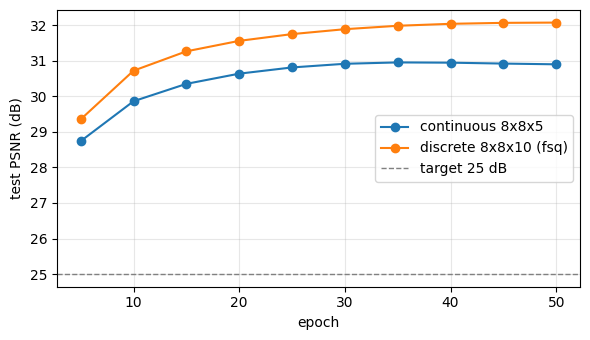

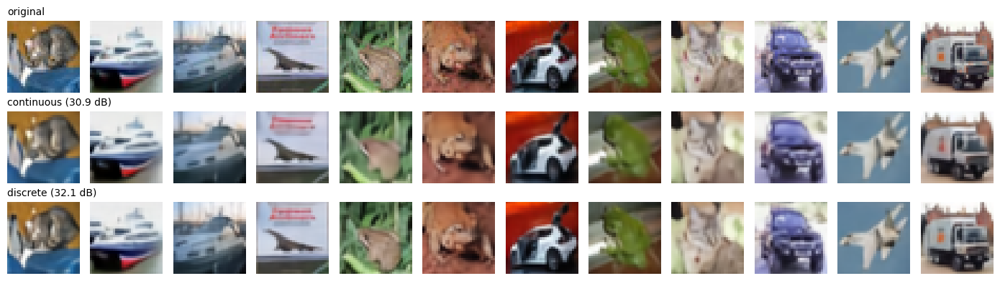

In [17]:
# PSNR curves
plt.figure(figsize=(6, 3.5))
plt.plot(cont_hist["epoch"], cont_hist["psnr"], marker="o", label="continuous 8x8x5")
plt.plot(disc_hist["epoch"], disc_hist["psnr"], marker="o", label=f"discrete 8x8x10 ({CFG['quantizer']})")
plt.axhline(25, color="gray", ls="--", lw=1, label="target 25 dB")
plt.xlabel("epoch"); plt.ylabel("test PSNR (dB)"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "psnr_curves.png"), dpi=150); plt.show()

# reconstruction grid: originals / continuous / discrete
with torch.no_grad():
    x = to_float(X_TEST[:12])
    rows = [x, cont_model.reconstruct(x), disc_model.reconstruct(x)]
titles = ["original", f"continuous ({cont_psnr:.1f} dB)", f"discrete ({disc_psnr:.1f} dB)"]
fig, axes = plt.subplots(3, 12, figsize=(14, 4))
for r, (imgs, t) in enumerate(zip(rows, titles)):
    imgs = ((imgs.float().clamp(-1, 1) + 1) / 2).permute(0, 2, 3, 1).cpu().numpy()
    for c in range(12):
        axes[r, c].imshow(imgs[c]); axes[r, c].axis("off")
    axes[r, 0].set_title(t, loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "reconstructions.png"), dpi=150); plt.show()

**Save latents for 4.2 and 4.3**

In [18]:
@torch.no_grad()
def extract(fn, x_u8, bs=500):
    return torch.cat([fn(x).cpu() for x in iterate(x_u8, bs, train=False)])

cont_model.eval(); disc_model.eval()
c_tr, c_te = extract(cont_model.encode, X_TRAIN), extract(cont_model.encode, X_TEST)
mu, sd = c_tr.mean(dim=(0, 2, 3)), c_tr.std(dim=(0, 2, 3))
np.savez(os.path.join(OUT_DIR, "continuous_latents.npz"),
         train=c_tr.numpy().astype(np.float32), test=c_te.numpy().astype(np.float32),
         mean=mu.numpy(), std=sd.numpy(), y_train=y_train_np, y_test=y_test_np)
print("continuous:", tuple(c_tr.shape), "channel mean", mu.numpy().round(3), "std", sd.numpy().round(3))

d_tr, d_te = extract(disc_model.encode, X_TRAIN), extract(disc_model.encode, X_TEST)
dtype = np.uint8 if CFG["quantizer"] == "fsq" else np.int16
np.savez(os.path.join(OUT_DIR, "discrete_latents.npz"),
         train=d_tr.numpy().astype(dtype), test=d_te.numpy().astype(dtype),
         quantizer=CFG["quantizer"], fsq_levels=CFG["fsq_levels"], vq_codebook_size=CFG["vq_codebook_size"],
         y_train=y_train_np, y_test=y_test_np)
if CFG["quantizer"] == "fsq":
    L = CFG["fsq_levels"]
    usage = [(np.bincount(d_tr[:, c].flatten().numpy(), minlength=L) > 0).sum() for c in range(d_tr.shape[1])]
    print("discrete (FSQ):", tuple(d_tr.shape), f"| levels used per channel (of {L}):", usage)
else:
    print("discrete (VQ):", tuple(d_tr.shape), "| codes used:", len(torch.unique(d_tr)), "/", CFG["vq_codebook_size"])

# sanity check: decoding the saved latents reproduces the reconstructions
with torch.no_grad():
    x = to_float(X_TEST[:8])
    a = (cont_model.decode(c_te[:8].to(DEVICE)) - cont_model.reconstruct(x)).abs().max().item()
    b = (disc_model.decode_codes(d_te[:8].to(DEVICE)) - disc_model.reconstruct(x)).abs().max().item()
print(f"decode-from-saved check: continuous max diff {a:.2e}, discrete max diff {b:.2e}")

continuous: (50000, 5, 8, 8) channel mean [ 0.361 -0.261 -0.016 -0.071  0.017] std [1.131 1.619 1.038 1.281 1.239]
discrete (FSQ): (50000, 10, 8, 8) | levels used per channel (of 7): [np.int64(7), np.int64(7), np.int64(7), np.int64(7), np.int64(7), np.int64(7), np.int64(7), np.int64(7), np.int64(7), np.int64(7)]
decode-from-saved check: continuous max diff 2.56e-06, discrete max diff 0.00e+00


In [2]:
!pip install -q pytorch-fid

In [3]:
import os, sys, glob, shutil, pickle, math, time, copy, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

QUICK_TEST = False      # True = ~5-minute smoke test with a tiny model

CFG = dict(
    seed=0,
    # transformer denoiser
    d_model=512, depth=8, heads=8, mlp_ratio=4, dropout=0.1,
    class_cond=True,          # True: class-conditional + classifier-free guidance; False: unconditional
    label_drop=0.1,           # fraction of training labels replaced by "no label" (enables guidance)
    # training
    epochs=60, batch_size=256, lr=4e-4, weight_decay=0.05, warmup_steps=2000,
    grad_clip=1.0, ema_decay=0.9999, flip_aug=True, sample_every=25,
    # sampling
    sample_steps=256, temperature=1.0, guidance=2.0,
    guidance_sweep=(1.0, 1.5, 2.0, 3.0), n_sweep=2000,
    # evaluation
    n_fid=10000,
)
if QUICK_TEST:
    CFG.update(d_model=128, depth=2, heads=4, epochs=2, warmup_steps=20, sample_every=1,
               sample_steps=16, guidance_sweep=(1.0, 2.0), n_sweep=200, n_fid=500)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./outputs"
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(CFG["seed"]); np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"]); torch.cuda.manual_seed_all(CFG["seed"])
torch.backends.cudnn.benchmark = True
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")


def grid_table(headers, rows, align):
    widths = [max(len(str(r[i])) for r in [headers] + rows) for i in range(len(headers))]
    sep = "+" + "+".join("-" * (w + 2) for w in widths) + "+"
    def line(vals):
        return "|" + "|".join(" " + (str(v).rjust(w) if a == "r" else str(v).ljust(w)) + " "
                              for v, w, a in zip(vals, widths, align)) + "|"
    out = [sep, line(headers), sep.replace("-", "=")]
    for r in rows:
        out += [line(r), sep]
    return "\n".join(out)

device: cuda Tesla T4


In [4]:
def find_one(pattern, roots=("/kaggle/input", ".")):
    for r in roots:
        hits = sorted(glob.glob(os.path.join(r, "**", pattern), recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"'{pattern}' not found - add your 4.1 notebook output via Add Input.")

src = find_one("ae_models.py")
if os.path.abspath(src) != os.path.abspath("ae_models.py"):
    shutil.copy(src, "ae_models.py")
sys.path.insert(0, os.getcwd())
from ae_models import *

ckpt_path = find_one("discrete_ae_*.pt")
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
AE_CFG = ckpt["cfg"]
ae = DiscreteAE(AE_CFG).to(DEVICE)
ae.load_state_dict(ckpt["model"])
ae.eval().requires_grad_(False)

QUANT = AE_CFG["quantizer"]
if QUANT == "fsq":
    V, C = AE_CFG["fsq_levels"], AE_CFG["disc_channels"]     # 7 values per element, 10 elements per position
else:
    V, C = AE_CFG["vq_codebook_size"], 1                     # one codebook index per position
P = 64                                                       # 8 x 8 latent positions
MASK_ID = V                                                  # extra token id meaning "masked"
N_CLASSES = 10
print(f"loaded {ckpt_path}\nquantizer={QUANT} | latent 8x8x{AE_CFG['disc_channels']} | "
      f"sequence = {P} positions x {C} elements, vocabulary {V} (+1 mask)")

loaded ./discrete_ae_fsq.pt
quantizer=fsq | latent 8x8x10 | sequence = 64 positions x 10 elements, vocabulary 7 (+1 mask)


In [24]:
def find_cifar_dir():
    for r in ["/kaggle/input", ".", "./data"]:
        hits = sorted(glob.glob(os.path.join(r, "**", "data_batch_1"), recursive=True))
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("CIFAR-10 not found - add the 'CIFAR-10 Python' dataset via Add Input.")

def load_split(d, names):
    xs, ys = [], []
    for n in names:
        with open(os.path.join(d, n), "rb") as f:
            b = pickle.load(f, encoding="bytes")
        xs.append(b[b"data"].reshape(-1, 3, 32, 32)); ys += list(b[b"labels"])
    return np.concatenate(xs), np.array(ys, dtype=np.int64)

CIFAR_DIR = find_cifar_dir()
x_train_np, y_train_np = load_split(CIFAR_DIR, [f"data_batch_{i}" for i in range(1, 6)])
x_test_np, y_test_np = load_split(CIFAR_DIR, ["test_batch"])
if QUICK_TEST:
    x_train_np, y_train_np = x_train_np[:2048], y_train_np[:2048]
    x_test_np, y_test_np = x_test_np[:1000], y_test_np[:1000]
X_TRAIN = torch.from_numpy(x_train_np).to(DEVICE)
Y_TRAIN = torch.from_numpy(y_train_np).to(DEVICE)
X_TEST = torch.from_numpy(x_test_np).to(DEVICE)

def to_float(u8):
    return u8.float().div(127.5).sub(1.0)

def to_uint8(x):
    return ((x.float().clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8)

def codes_to_tokens(codes):           # AE codes -> B x 64 x C
    if QUANT == "fsq":
        return codes.flatten(2).transpose(1, 2).contiguous()
    return codes.flatten(1).unsqueeze(-1)

def tokens_to_codes(tok):             # B x 64 x C -> AE codes
    B = tok.shape[0]
    if QUANT == "fsq":
        return tok.transpose(1, 2).reshape(B, C, 8, 8)
    return tok.squeeze(-1).reshape(B, 8, 8)

@torch.no_grad()
def encode_tokens(x_u8, flip=False, bs=500):
    out = []
    for i in range(0, len(x_u8), bs):
        x = to_float(x_u8[i:i + bs])
        if flip:
            x = x.flip(3)
        out.append(codes_to_tokens(ae.encode(x)).to(torch.int16))
    return torch.cat(out)

t0 = time.time()
TOK = encode_tokens(X_TRAIN)
LAB = Y_TRAIN.clone()
if CFG["flip_aug"]:
    TOK = torch.cat([TOK, encode_tokens(X_TRAIN, flip=True)])
    LAB = torch.cat([LAB, Y_TRAIN])
print(f"tokens: {tuple(TOK.shape)}  (images x positions x elements), values {int(TOK.min())}..{int(TOK.max())}, "
      f"{time.time() - t0:.0f}s")

tokens: (100000, 64, 10)  (images x positions x elements), values 0..6, 67s


In [25]:
from pytorch_fid.inception import InceptionV3
from pytorch_fid.fid_score import calculate_frechet_distance

inception = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(DEVICE).eval()

@torch.no_grad()
def inception_feats(u8, bs=250):
    feats = []
    for i in range(0, len(u8), bs):
        x = u8[i:i + bs].to(DEVICE).float() / 255.0          # inception expects [0, 1]
        feats.append(inception(x)[0].flatten(1).double().cpu())
    return torch.cat(feats).numpy()

def fid_vs_real(u8):
    f = inception_feats(u8)
    return float(calculate_frechet_distance(f.mean(0), np.cov(f, rowvar=False), MU_REAL, SIG_REAL))

t0 = time.time()
f_real = inception_feats(X_TRAIN)
MU_REAL, SIG_REAL = f_real.mean(0), np.cov(f_real, rowvar=False)
np.savez(os.path.join(OUT_DIR, "cifar10_train_inception_stats.npz"), mu=MU_REAL, sigma=SIG_REAL)
print(f"real statistics from {len(X_TRAIN)} training images ({time.time() - t0:.0f}s)")

with torch.no_grad():
    recon = torch.cat([to_uint8(ae.reconstruct(to_float(X_TEST[i:i + 500]))).cpu()
                       for i in range(0, len(X_TEST), 500)])
RFID = fid_vs_real(recon)
print(f"reconstruction FID (autoencoder floor, {len(recon)} test images): {RFID:.2f}")

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 196MB/s] 


real statistics from 50000 training images (230s)
reconstruction FID (autoencoder floor, 10000 test images): 12.60


In [5]:
class Block(nn.Module):
    def __init__(self, d, heads, mlp_ratio, dropout):
        super().__init__()
        self.heads, self.p = heads, dropout
        self.ln1, self.qkv, self.proj = nn.LayerNorm(d), nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, mlp_ratio * d), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(mlp_ratio * d, d))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, N, 3, self.heads, D // self.heads).permute(2, 0, 3, 1, 4)
        h = F.scaled_dot_product_attention(q, k, v, dropout_p=self.p if self.training else 0.0)
        x = x + self.drop(self.proj(h.transpose(1, 2).reshape(B, N, D)))
        return x + self.drop(self.mlp(self.ln2(x)))


class MaskedDiffusionTransformer(nn.Module):
    def __init__(self, V, C, P, n_classes, cfg):
        super().__init__()
        d = cfg["d_model"]
        self.V, self.C, self.P = V, C, P
        self.tok_emb = nn.Embedding(C * (V + 1), d)                  # one table per element, incl. [MASK]
        self.register_buffer("offset", torch.arange(C) * (V + 1), persistent=False)
        self.cls_emb = nn.Embedding(n_classes + 1, d)                # last id = "no label"
        self.pos_emb = nn.Parameter(torch.zeros(1, P + 1, d))
        self.blocks = nn.ModuleList([Block(d, cfg["heads"], cfg["mlp_ratio"], cfg["dropout"])
                                     for _ in range(cfg["depth"])])
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, C * V)
        self.apply(self._init)
        nn.init.normal_(self.pos_emb, std=0.02)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02); nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, tok, y):       # tok: B x P x C (MASK_ID = masked), y: B (n_classes = no label)
        h = self.tok_emb(tok + self.offset).sum(2)
        h = torch.cat([self.cls_emb(y)[:, None], h], 1) + self.pos_emb
        for blk in self.blocks:
            h = blk(h)
        return self.head(self.ln_f(h[:, 1:])).view(tok.shape[0], self.P, self.C, self.V)


model = MaskedDiffusionTransformer(V, C, P, N_CLASSES, CFG).to(DEVICE)
print(f"denoiser parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

denoiser parameters: 25.3M


In [31]:
def apply_mask(tok):
    t = torch.rand(tok.shape[0], 1, 1, device=tok.device).clamp_min(1.0 / (P * C))
    m = torch.rand(tok.shape, device=tok.device) < t
    return torch.where(m, torch.full_like(tok, MASK_ID), tok), m


@torch.no_grad()
def sample_tokens(net, y, steps, temperature=1.0, guidance=1.0):
    B = y.shape[0]
    null = torch.full_like(y, N_CLASSES)
    if not CFG["class_cond"]:
        y, guidance = null, 1.0
    x = torch.full((B, P, C), MASK_ID, dtype=torch.long, device=DEVICE)
    for i in range(steps):
        t, s = 1 - i / steps, 1 - (i + 1) / steps
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            if guidance != 1.0:
                lc, lu = net(torch.cat([x, x]), torch.cat([y, null])).float().chunk(2)
                logits = lu + guidance * (lc - lu)
            else:
                logits = net(x, y).float()
        probs = F.softmax(logits / temperature, dim=-1)
        x0 = torch.multinomial(probs.view(-1, V), 1).view(B, P, C)
        reveal = (x == MASK_ID) & (torch.rand(x.shape, device=DEVICE) < (t - s) / t)
        x = torch.where(reveal, x0, x)
    return x


@torch.no_grad()
def generate(net, n, bs=500, **kw):
    # class-balanced labels 0..9, decoded to uint8 images (N x 3 x 32 x 32, on CPU)
    imgs = []
    for i in range(0, n, bs):
        y = torch.arange(i, min(n, i + bs), device=DEVICE) % N_CLASSES
        tok = sample_tokens(net, y, **kw)
        imgs.append(to_uint8(ae.decode_codes(tokens_to_codes(tok))).cpu())
    return torch.cat(imgs)


def show_grid(u8, nrow, title, path):
    n = len(u8)
    fig, axes = plt.subplots(math.ceil(n / nrow), nrow, figsize=(nrow * 1.1, math.ceil(n / nrow) * 1.1))
    for ax, img in zip(axes.flat, u8):
        ax.imshow(img.permute(1, 2, 0).numpy())
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

epoch   1/60 | loss 1.7866 | masked acc 0.246 | lr 7.82e-05 | 1.9 min
epoch   2/60 | loss 1.7617 | masked acc 0.255 | lr 1.56e-04 | 3.7 min
epoch   3/60 | loss 1.7392 | masked acc 0.264 | lr 2.34e-04 | 5.5 min
epoch   4/60 | loss 1.7191 | masked acc 0.271 | lr 3.12e-04 | 7.4 min
epoch   5/60 | loss 1.7006 | masked acc 0.278 | lr 3.90e-04 | 9.2 min
epoch   6/60 | loss 1.6874 | masked acc 0.283 | lr 4.00e-04 | 11.1 min
epoch   7/60 | loss 1.6773 | masked acc 0.288 | lr 3.99e-04 | 12.9 min
epoch   8/60 | loss 1.6698 | masked acc 0.291 | lr 3.97e-04 | 14.7 min
epoch   9/60 | loss 1.6615 | masked acc 0.295 | lr 3.95e-04 | 16.6 min
epoch  10/60 | loss 1.6578 | masked acc 0.296 | lr 3.92e-04 | 18.4 min
epoch  11/60 | loss 1.6538 | masked acc 0.298 | lr 3.89e-04 | 20.3 min
epoch  12/60 | loss 1.6492 | masked acc 0.300 | lr 3.85e-04 | 22.1 min
epoch  13/60 | loss 1.6466 | masked acc 0.301 | lr 3.80e-04 | 24.0 min
epoch  14/60 | loss 1.6426 | masked acc 0.303 | lr 3.75e-04 | 25.8 min
epoch  15/6

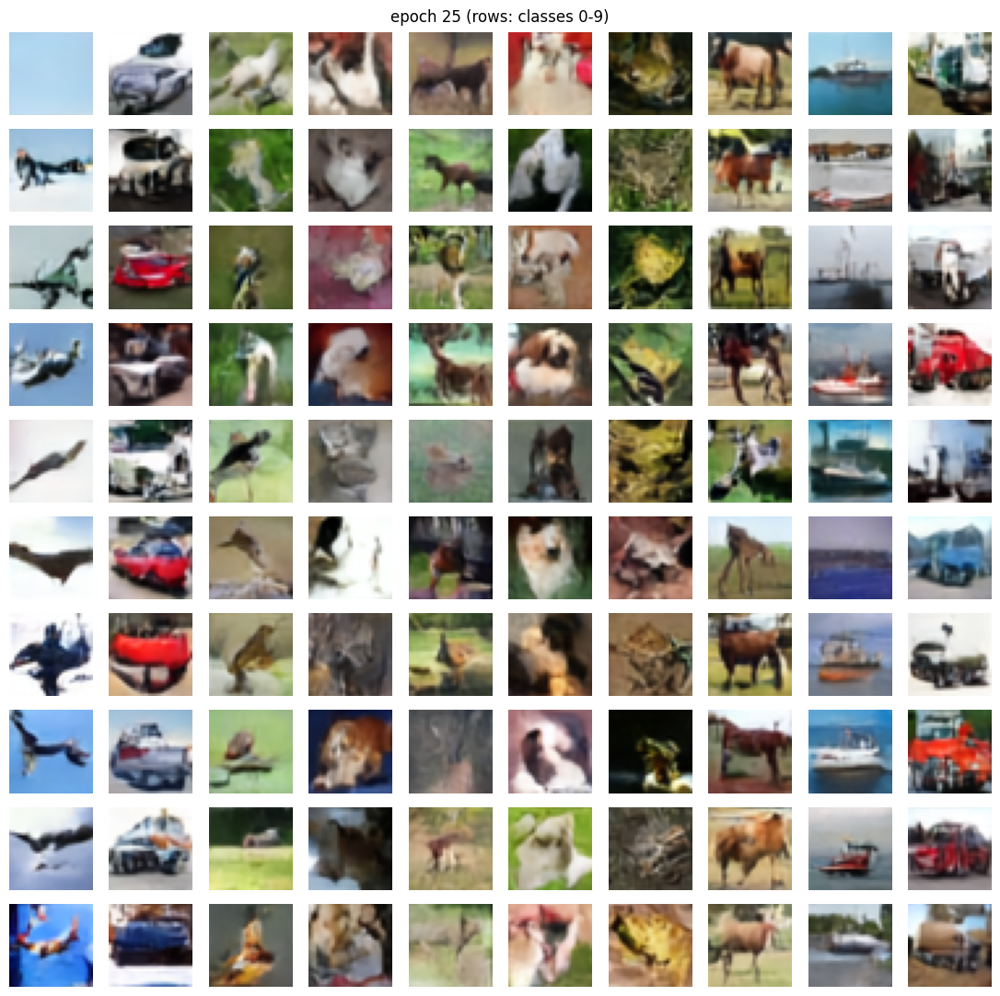

epoch  26/60 | loss 1.6209 | masked acc 0.312 | lr 2.76e-04 | 48.1 min
epoch  27/60 | loss 1.6203 | masked acc 0.312 | lr 2.65e-04 | 49.9 min
epoch  28/60 | loss 1.6180 | masked acc 0.313 | lr 2.55e-04 | 51.7 min
epoch  29/60 | loss 1.6174 | masked acc 0.313 | lr 2.44e-04 | 53.6 min
epoch  30/60 | loss 1.6143 | masked acc 0.315 | lr 2.33e-04 | 55.4 min
epoch  31/60 | loss 1.6149 | masked acc 0.315 | lr 2.22e-04 | 57.3 min
epoch  32/60 | loss 1.6139 | masked acc 0.315 | lr 2.10e-04 | 59.1 min
epoch  33/60 | loss 1.6125 | masked acc 0.315 | lr 1.99e-04 | 61.0 min
epoch  34/60 | loss 1.6111 | masked acc 0.316 | lr 1.88e-04 | 62.8 min
epoch  35/60 | loss 1.6087 | masked acc 0.317 | lr 1.77e-04 | 64.6 min
epoch  36/60 | loss 1.6094 | masked acc 0.317 | lr 1.66e-04 | 66.5 min
epoch  37/60 | loss 1.6075 | masked acc 0.318 | lr 1.55e-04 | 68.3 min
epoch  38/60 | loss 1.6083 | masked acc 0.317 | lr 1.44e-04 | 70.2 min
epoch  39/60 | loss 1.6055 | masked acc 0.318 | lr 1.33e-04 | 72.0 min
epoch 

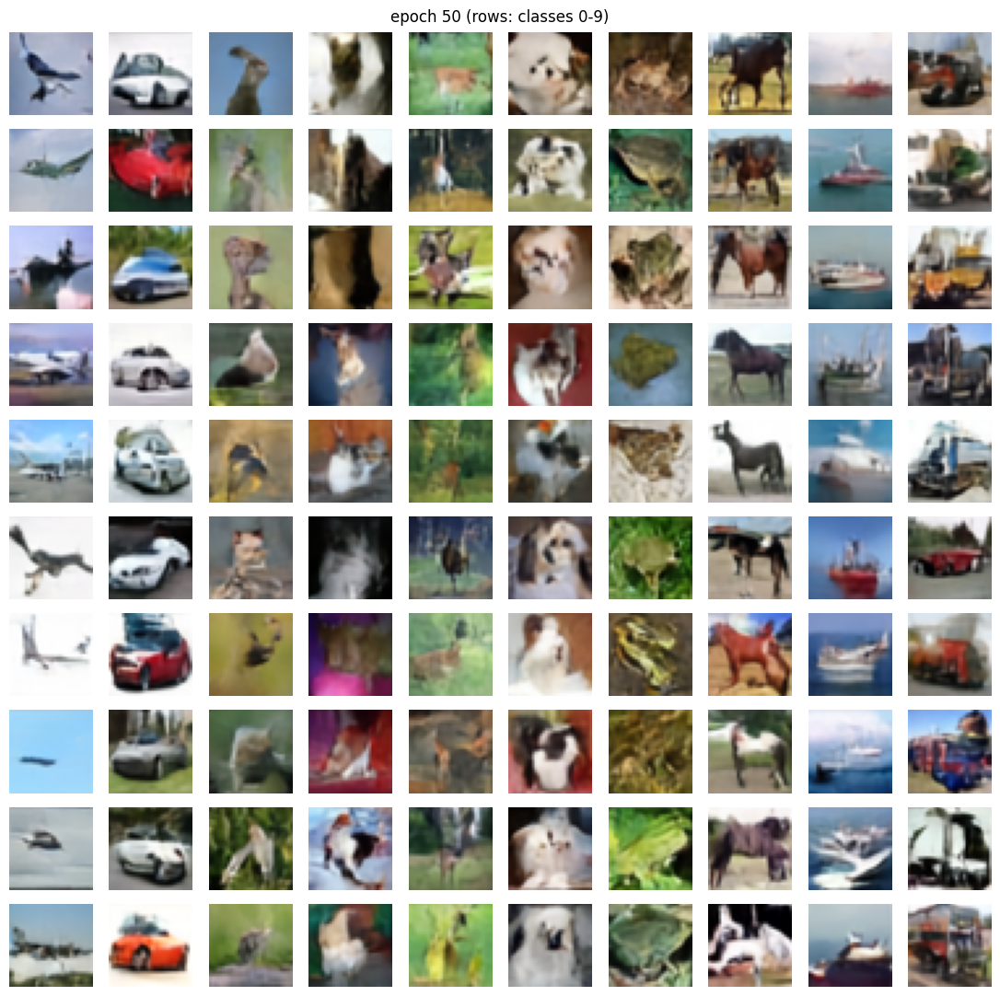

epoch  51/60 | loss 1.5985 | masked acc 0.321 | lr 3.34e-05 | 94.2 min
epoch  52/60 | loss 1.5973 | masked acc 0.322 | lr 2.82e-05 | 96.1 min
epoch  53/60 | loss 1.5972 | masked acc 0.322 | lr 2.35e-05 | 97.9 min
epoch  54/60 | loss 1.5974 | masked acc 0.322 | lr 1.95e-05 | 99.8 min
epoch  55/60 | loss 1.5981 | masked acc 0.322 | lr 1.60e-05 | 101.6 min
epoch  56/60 | loss 1.5959 | masked acc 0.322 | lr 1.31e-05 | 103.5 min
epoch  57/60 | loss 1.5963 | masked acc 0.322 | lr 1.09e-05 | 105.3 min
epoch  58/60 | loss 1.5961 | masked acc 0.323 | lr 9.28e-06 | 107.1 min
epoch  59/60 | loss 1.5964 | masked acc 0.322 | lr 8.32e-06 | 109.0 min
epoch  60/60 | loss 1.5963 | masked acc 0.322 | lr 8.00e-06 | 110.8 min


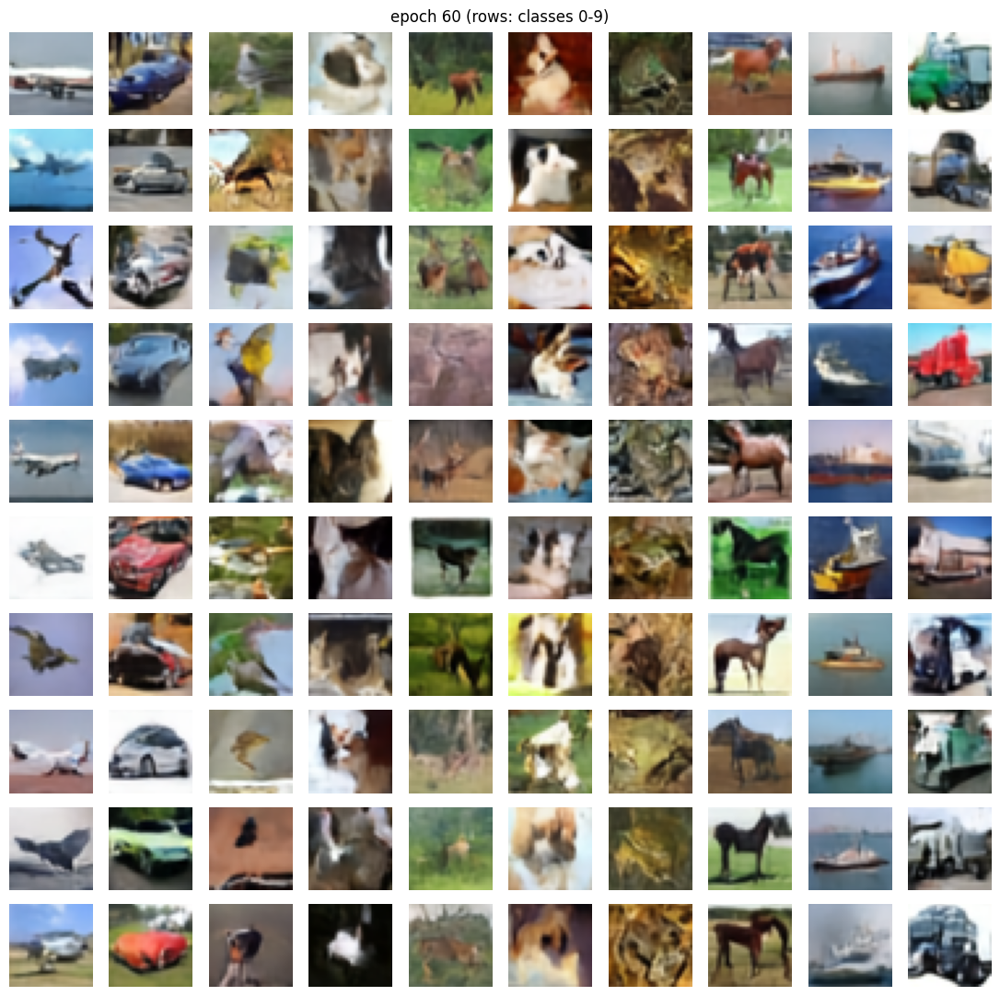

saved /kaggle/working/latent_diffusion.pt


In [35]:
class EMA:
    def __init__(self, net, decay):
        self.model = copy.deepcopy(net).eval()
        self.decay = decay
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, net, step):
        d = min(self.decay, (1 + step) / (10 + step))
        for pe, p in zip(self.model.parameters(), net.parameters()):
            pe.lerp_(p.detach(), 1 - d)


def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


decay, no_decay = [], []
for n_, p in model.named_parameters():
    (no_decay if p.ndim < 2 or "emb" in n_ else decay).append(p)
opt = torch.optim.AdamW([{"params": decay, "weight_decay": CFG["weight_decay"]},
                         {"params": no_decay, "weight_decay": 0.0}], lr=CFG["lr"], betas=(0.9, 0.95))
steps_per_epoch = len(TOK) // CFG["batch_size"]
total_steps = steps_per_epoch * CFG["epochs"]
warm = CFG["warmup_steps"]
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: (s + 1) / warm if s < warm else
    0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(1.0, (s - warm) / max(1, total_steps - warm)))))
scaler = make_scaler()
ema = EMA(model, CFG["ema_decay"])
hist = {"epoch": [], "loss": [], "acc": []}
ckpt_out = os.path.join(OUT_DIR, "latent_diffusion.pt")

step, t0 = 0, time.time()
for epoch in range(1, CFG["epochs"] + 1):
    model.train()
    perm = torch.randperm(len(TOK), device=DEVICE)
    tot_loss, tot_acc, nb = torch.zeros((), device=DEVICE), torch.zeros((), device=DEVICE), 0
    for i in range(steps_per_epoch):
        idx = perm[i * CFG["batch_size"]:(i + 1) * CFG["batch_size"]]
        tok, y = TOK[idx].long(), LAB[idx]
        if CFG["class_cond"]:
            y = torch.where(torch.rand(y.shape, device=DEVICE) < CFG["label_drop"],
                            torch.full_like(y, N_CLASSES), y)
        else:
            y = torch.full_like(y, N_CLASSES)
        xt, m = apply_mask(tok)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(xt, y)
        lm = logits[m].float()
        loss = F.cross_entropy(lm, tok[m])
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(opt); scaler.update(); sched.step()
        ema.update(model, step)
        tot_loss += loss.detach(); tot_acc += (lm.argmax(-1) == tok[m]).float().mean(); nb += 1; step += 1

    hist["epoch"].append(epoch); hist["loss"].append((tot_loss / nb).item()); hist["acc"].append((tot_acc / nb).item())
    print(f"epoch {epoch:3d}/{CFG['epochs']} | loss {hist['loss'][-1]:.4f} | masked acc {hist['acc'][-1]:.3f} "
          f"| lr {sched.get_last_lr()[0]:.2e} | {(time.time() - t0) / 60:.1f} min")

    if epoch % CFG["sample_every"] == 0 or epoch == CFG["epochs"]:
        torch.save({"cfg": CFG, "ae_ckpt": ckpt_path, "model": ema.model.state_dict(), "hist": hist}, ckpt_out)
        imgs = generate(ema.model, 100, bs=100, steps=min(64, CFG["sample_steps"]), guidance=CFG["guidance"])
        show_grid(imgs, 10, f"epoch {epoch} (rows: classes 0-9)", os.path.join(OUT_DIR, f"samples_epoch{epoch:03d}.png"))

net = ema.model
print("saved", ckpt_out)

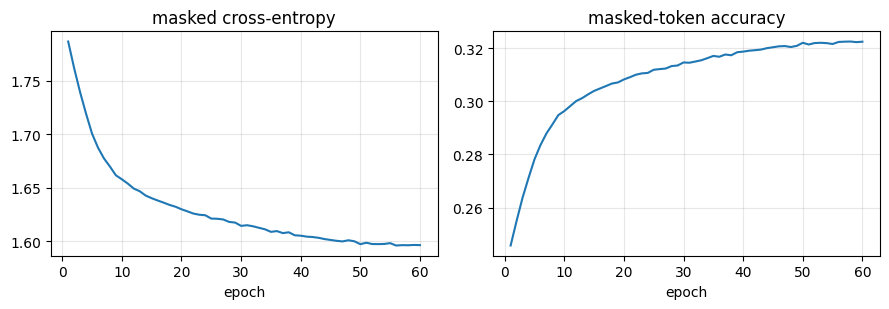

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(hist["epoch"], hist["loss"]); ax[0].set_title("masked cross-entropy"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["epoch"], hist["acc"]); ax[1].set_title("masked-token accuracy"); ax[1].set_xlabel("epoch")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "diffusion_training_curves.png"), dpi=150); plt.show()

In [41]:
if CFG["class_cond"]:
    rows, best = [], None
    for g in CFG["guidance_sweep"]:
        t0 = time.time()
        fid_g = fid_vs_real(generate(net, CFG["n_sweep"], steps=CFG["sample_steps"], guidance=g))
        rows.append([f"{g:.1f}", f"{fid_g:.2f}", f"{time.time() - t0:.0f}s"])
        if best is None or fid_g < best[1]:
            best = (g, fid_g)
    print(grid_table(["guidance", f"FID ({CFG['n_sweep']} samples)", "time"], rows, ["r", "r", "r"]))
    CFG["guidance"] = best[0]
    print(f"using guidance = {best[0]}")
else:
    print("unconditional model - no guidance sweep")

+----------+--------------------+------+
| guidance | FID (2000 samples) | time |
+==========+====================+======+
|      1.0 |              50.69 | 191s |
+----------+--------------------+------+
|      1.5 |              42.66 | 363s |
+----------+--------------------+------+
|      2.0 |              40.49 | 364s |
+----------+--------------------+------+
|      3.0 |              39.18 | 364s |
+----------+--------------------+------+
using guidance = 3.0


In [42]:
t0 = time.time()
gen = generate(net, CFG["n_fid"], steps=CFG["sample_steps"], guidance=CFG["guidance"],
               temperature=CFG["temperature"])
FID = fid_vs_real(gen)
np.savez_compressed(os.path.join(OUT_DIR, "generated_samples.npz"), images=gen.numpy())

rows = [
    ["Autoencoder reconstructions (floor)", f"{len(recon):,}", f"{RFID:.2f}", "-"],
    ["Discrete latent diffusion (generated)", f"{len(gen):,}", f"{FID:.2f}", "PASS" if FID < 40 else "FAIL"],
]
print(grid_table(["model", "images", "FID", "target < 40"], rows, ["l", "r", "r", "l"]))
print(f"settings: {CFG['sample_steps']} steps, guidance {CFG['guidance']}, temperature {CFG['temperature']}, "
      f"class_cond={CFG['class_cond']} | sampling + FID took {(time.time() - t0) / 60:.1f} min")

+---------------------------------------+--------+-------+-------------+
| model                                 | images |   FID | target < 40 |
+=======================================+========+=======+=============+
| Autoencoder reconstructions (floor)   | 10,000 | 12.60 | -           |
+---------------------------------------+--------+-------+-------------+
| Discrete latent diffusion (generated) | 10,000 | 28.94 | PASS        |
+---------------------------------------+--------+-------+-------------+
settings: 256 steps, guidance 3.0, temperature 1.0, class_cond=True | sampling + FID took 29.4 min


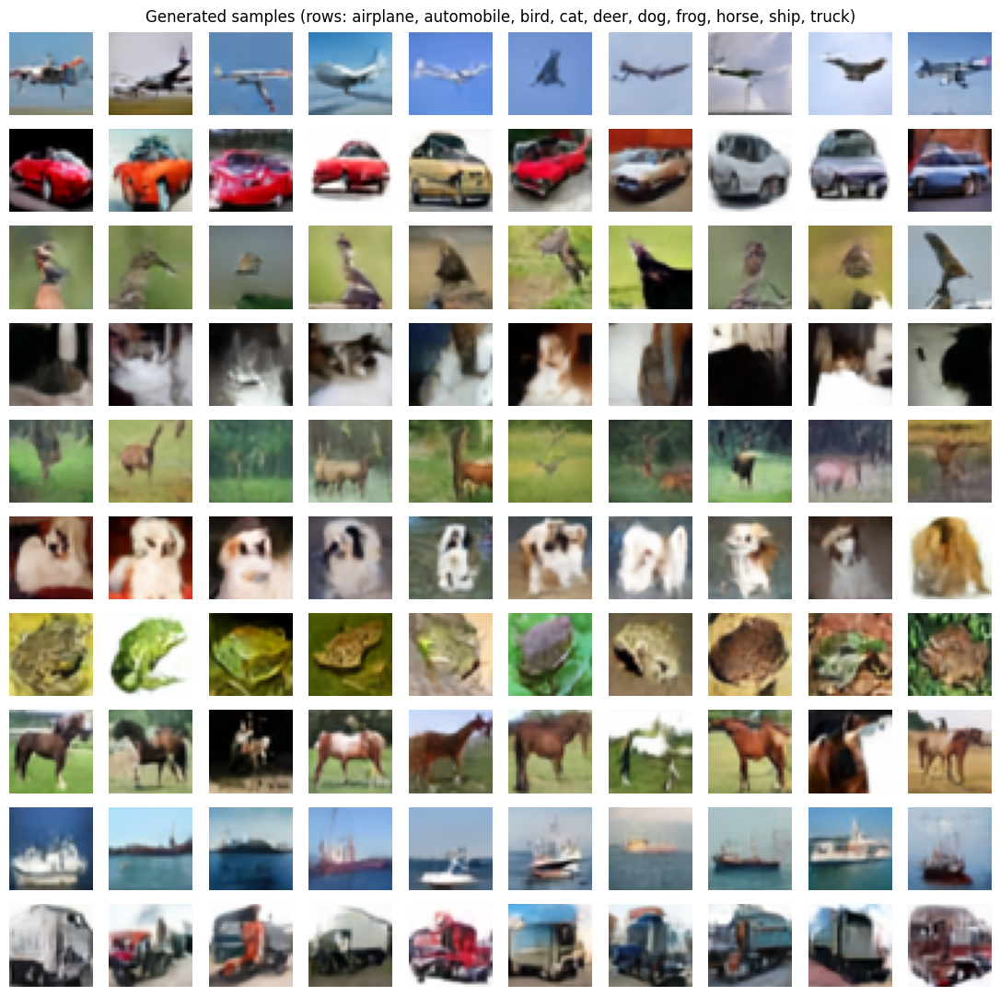

In [43]:
# 10 x 10 grid of final samples: one row per class (airplane, car, bird, cat, deer, dog, frog, horse, ship, truck)
classes = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
order = torch.cat([torch.arange(c, 100, 10) for c in range(10)])     # first 10 samples of each class
show_grid(gen[order], 10, "Generated samples (rows: " + ", ".join(classes) + ")",
          os.path.join(OUT_DIR, "final_samples.png"))

In [7]:
import html as _html
from IPython.display import HTML, display

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def fmt_n(n):
    return f"{n / 1e6:.2f}M" if n >= 1e6 else (f"{n / 1e3:.1f}K" if n >= 1e3 else str(n))

def show_table(headers, rows, title="", align=None):
    # Renders a real HTML table with a border on every cell.
    align = align or ["left"] * len(headers)
    cell = "border:1px solid #777; padding:5px 12px;"
    head = "".join(f'<th style="{cell} background:#e8e8e8; color:#000; text-align:{a}">{_html.escape(str(h))}</th>'
                   for h, a in zip(headers, align))
    body = "".join("<tr>" + "".join(f'<td style="{cell} text-align:{a}">{_html.escape(str(v))}</td>'
                                    for v, a in zip(r, align)) + "</tr>" for r in rows)
    display(HTML(f'<div style="font-weight:bold; margin:6px 0">{_html.escape(title)}</div>'
                 f'<table style="border-collapse:collapse; font-size:13px">'
                 f'<tr>{head}</tr>{body}</table>'))

def save_table_png(headers, rows, title, path):
    # Same table as an image for the report.
    fig, ax = plt.subplots(figsize=(13, 0.42 * (len(rows) + 2)))
    ax.axis("off")
    tbl = ax.table(cellText=[[str(v) for v in r] for r in rows], colLabels=headers,
                   loc="center", cellLoc="left", colLoc="left")
    tbl.auto_set_font_size(False); tbl.set_fontsize(9)
    tbl.auto_set_column_width(list(range(len(headers))))
    for (r, c), cell_ in tbl.get_celld().items():
        if r == 0:
            cell_.set_facecolor("#e8e8e8"); cell_.set_text_props(weight="bold")
    ax.set_title(title, fontsize=11, fontweight="bold")
    plt.savefig(path, dpi=200, bbox_inches="tight"); plt.close(fig)
    print("saved", path)


@torch.no_grad()
def diffusion_architecture_rows(net):
    d, heads = CFG["d_model"], CFG["heads"]
    rows, hooks = [], []

    def add(stage, label, mod, take=lambda o: o):
        def hook(m, inp, out):
            rows.append([stage, label, tuple(take(out).shape[1:]), count_params(m)])
        hooks.append(mod.register_forward_hook(hook))

    add("Embedding", f"Element embeddings ({C} tables x {V + 1} ids incl. MASK), summed",
        net.tok_emb, lambda o: o.sum(2))
    add("Embedding", f"Class embedding ({N_CLASSES} classes + 'no label')",
        net.cls_emb, lambda o: o[:, None])
    for blk in net.blocks:
        add("Transformer", f"Block: LN, {heads}-head self-attention, LN, MLP {d}-{4 * d}-{d}", blk)
    add("Output", "Final LayerNorm", net.ln_f)
    add("Output", f"Linear head {d} -> {C} x {V}", net.head)

    tok = torch.full((2, P, C), MASK_ID, dtype=torch.long, device=DEVICE)
    y = torch.zeros(2, dtype=torch.long, device=DEVICE)
    was_training = net.training
    net.eval()
    out = net(tok, y)
    net.train(was_training)
    for h in hooks:
        h.remove()

    rows.insert(2, ["Embedding", "Prepend class token + position embedding", (P + 1, d), net.pos_emb.numel()])

    merged = []
    for r in rows:
        if merged and merged[-1][:3] == r[:3]:
            merged[-1][3] += r[3]; merged[-1][4] += 1
        else:
            merged.append(r + [1])

    table, prev = [["Input", f"Latent tokens (masked), ints 0..{V - 1} or MASK={MASK_ID}", str((P, C)), "-"]], "Input"
    for stage, label, shp, n, cnt in merged:
        table.append([stage if stage != prev else "", f"{cnt} x {label}" if cnt > 1 else label, str(shp), fmt_n(n)])
        prev = stage
    table.append(["", "Reshape (drop class token) -> logits", str(tuple(out.shape[1:])), "-"])
    table.append(["Total", "", "", fmt_n(count_params(net))])
    return table


headers = ["Stage", "Block", "Output shape", "Params"]
rows = diffusion_architecture_rows(model)
title = f"Masked Discrete Diffusion Transformer (sequence {P} positions x {C} elements, vocab {V} + MASK)"
show_table(headers, rows, title, align=["left", "left", "left", "right"])
save_table_png(headers, rows, title, os.path.join(OUT_DIR, "architecture_diffusion.png"))

Stage,Block,Output shape,Params
Input,"Latent tokens (masked), ints 0..6 or MASK=7","(64, 10)",-
Embedding,"Element embeddings (10 tables x 8 ids incl. MASK), summed","(64, 512)",41.0K
,Class embedding (10 classes + 'no label'),"(1, 512)",5.6K
,Prepend class token + position embedding,"(65, 512)",33.3K
Transformer,"8 x Block: LN, 8-head self-attention, LN, MLP 512-2048-512","(65, 512)",25.22M
Output,Final LayerNorm,"(64, 512)",1.0K
,Linear head 512 -> 10 x 7,"(64, 70)",35.9K
,Reshape (drop class token) -> logits,"(64, 10, 7)",-
Total,,,25.34M


saved /kaggle/working/architecture_diffusion.png


In [8]:
!pip install -q pytorch-fid

In [10]:
import os, sys, glob, shutil, pickle, math, time, copy, random, html
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import HTML, display

QUICK_TEST = False      # True = ~5-minute smoke test with a tiny model

CFG = dict(
    seed=0,
    d_model=512, depth=8, heads=8, mlp_ratio=4, dropout=0.1,          # causal transformer
    class_cond=True, label_drop=0.1,
    head_width=512, head_depth=3, diff_T=1000, diff_mul=4, head_steps=100,   # per-token diffusion head
    epochs=60, batch_size=256, lr=4e-4, weight_decay=0.05, warmup_steps=1000,
    grad_clip=1.0, ema_decay=0.9995, flip_aug=True,
    guidance=2.0, temperature=1.0, n_sweep=2000, n_fid=10000,
)
if QUICK_TEST:
    CFG.update(d_model=128, depth=2, heads=4, head_width=128, head_depth=2, head_steps=20,
               epochs=2, warmup_steps=20, n_sweep=200, n_fid=500)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./outputs"
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(CFG["seed"]); np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"]); torch.cuda.manual_seed_all(CFG["seed"])
print("device:", DEVICE)


def show_table(headers, rows, title="", align=None):
    align = align or ["left"] * len(headers)
    cell = "border:1px solid #777; padding:5px 12px;"
    head = "".join(f'<th style="{cell} background:#e8e8e8; color:#000; text-align:{a}">{html.escape(str(h))}</th>'
                   for h, a in zip(headers, align))
    body = "".join("<tr>" + "".join(f'<td style="{cell} text-align:{a}">{html.escape(str(v))}</td>'
                                    for v, a in zip(r, align)) + "</tr>" for r in rows)
    display(HTML(f'<div style="font-weight:bold; margin:6px 0">{html.escape(title)}</div>'
                 f'<table style="border-collapse:collapse; font-size:13px"><tr>{head}</tr>{body}</table>'))

device: cuda


In [11]:
def find_one(pattern, roots=("/kaggle/input", ".")):
    for r in roots:
        hits = sorted(glob.glob(os.path.join(r, "**", pattern), recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"'{pattern}' not found - add your 4.1 notebook output via Add Input.")

src = find_one("ae_models.py")
if os.path.abspath(src) != os.path.abspath("ae_models.py"):
    shutil.copy(src, "ae_models.py")
sys.path.insert(0, os.getcwd())
from ae_models import *

ckpt_path = find_one("continuous_ae.pt")
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
AE_CFG = ckpt["cfg"]
ae = ContinuousAE(AE_CFG).to(DEVICE)
ae.load_state_dict(ckpt["model"])
ae.eval().requires_grad_(False)

D = AE_CFG["cont_channels"]      # 5 numbers per latent position
P = 64                           # 8 x 8 positions = sequence length
N_CLASSES = 10
print(f"loaded {ckpt_path} | latent 8x8x{D} -> sequence of {P} tokens, each a {D}-dim vector")

loaded ./continuous_ae.pt | latent 8x8x5 -> sequence of 64 tokens, each a 5-dim vector


In [12]:
def find_cifar_dir():
    for r in ["/kaggle/input", ".", "./data"]:
        hits = sorted(glob.glob(os.path.join(r, "**", "data_batch_1"), recursive=True))
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("CIFAR-10 not found - add the 'CIFAR-10 Python' dataset via Add Input.")

def load_split(d, names):
    xs, ys = [], []
    for n in names:
        with open(os.path.join(d, n), "rb") as f:
            b = pickle.load(f, encoding="bytes")
        xs.append(b[b"data"].reshape(-1, 3, 32, 32)); ys += list(b[b"labels"])
    return np.concatenate(xs), np.array(ys, dtype=np.int64)

CIFAR_DIR = find_cifar_dir()
x_train_np, y_train_np = load_split(CIFAR_DIR, [f"data_batch_{i}" for i in range(1, 6)])
x_test_np, y_test_np = load_split(CIFAR_DIR, ["test_batch"])
if QUICK_TEST:
    x_train_np, y_train_np = x_train_np[:2048], y_train_np[:2048]
    x_test_np, y_test_np = x_test_np[:1000], y_test_np[:1000]
X_TRAIN = torch.from_numpy(x_train_np).to(DEVICE)
Y_TRAIN = torch.from_numpy(y_train_np).to(DEVICE)
X_TEST = torch.from_numpy(x_test_np).to(DEVICE)

def to_float(u8):
    return u8.float().div(127.5).sub(1.0)

def to_uint8(x):
    return ((x.float().clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8)

@torch.no_grad()
def encode_tokens(x_u8, flip=False, bs=500):
    out = []
    for i in range(0, len(x_u8), bs):
        x = to_float(x_u8[i:i + bs])
        if flip:
            x = x.flip(3)
        z = ae.encode(x).float()                          # B x 5 x 8 x 8
        out.append(z.flatten(2).transpose(1, 2))           # B x 64 x 5 (raster order)
    return torch.cat(out)

t0 = time.time()
Z = encode_tokens(X_TRAIN)
LAB = Y_TRAIN.clone()
if CFG["flip_aug"]:
    Z = torch.cat([Z, encode_tokens(X_TRAIN, flip=True)])
    LAB = torch.cat([LAB, Y_TRAIN])

MU = Z.mean(dim=(0, 1))
SD = Z.std(dim=(0, 1))
TOKS = (Z - MU) / SD                                       # standardised tokens
CLIP = float(TOKS.abs().max()) * 1.1                        # range guard used during sampling
del Z

def tokens_to_latent(tok):                                  # B x 64 x 5 (standardised) -> B x 5 x 8 x 8
    z = tok * SD + MU
    return z.transpose(1, 2).reshape(tok.shape[0], D, 8, 8)

print(f"tokens: {tuple(TOKS.shape)} | channel mean {MU.cpu().numpy().round(3)} | std {SD.cpu().numpy().round(3)} "
      f"| {time.time() - t0:.0f}s")

tokens: (100000, 64, 5) | channel mean [ 0.359 -0.26  -0.017 -0.072  0.015] | std [1.13  1.619 1.038 1.281 1.238] | 55s


In [13]:
from pytorch_fid.inception import InceptionV3
from pytorch_fid.fid_score import calculate_frechet_distance

inception = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(DEVICE).eval()

@torch.no_grad()
def inception_feats(u8, bs=250):
    feats = []
    for i in range(0, len(u8), bs):
        x = u8[i:i + bs].to(DEVICE).float() / 255.0
        feats.append(inception(x)[0].flatten(1).double().cpu())
    return torch.cat(feats).numpy()

def fid_vs_real(u8):
    f = inception_feats(u8)
    return float(calculate_frechet_distance(f.mean(0), np.cov(f, rowvar=False), MU_REAL, SIG_REAL))

t0 = time.time()
f_real = inception_feats(X_TRAIN)
MU_REAL, SIG_REAL = f_real.mean(0), np.cov(f_real, rowvar=False)
print(f"real statistics from {len(X_TRAIN)} training images ({time.time() - t0:.0f}s)")

with torch.no_grad():
    recon = torch.cat([to_uint8(ae.reconstruct(to_float(X_TEST[i:i + 500]))).cpu()
                       for i in range(0, len(X_TEST), 500)])
RFID = fid_vs_real(recon)
print(f"reconstruction FID (continuous autoencoder floor, {len(recon)} test images): {RFID:.2f}")

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 211MB/s]


real statistics from 50000 training images (199s)
reconstruction FID (continuous autoencoder floor, 10000 test images): 29.85


In [14]:
class Block(nn.Module):
    def __init__(self, d, heads, mlp_ratio, dropout):
        super().__init__()
        self.heads, self.p = heads, dropout
        self.ln1, self.qkv, self.proj = nn.LayerNorm(d), nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, mlp_ratio * d), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(mlp_ratio * d, d))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        B, N, Dm = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, N, 3, self.heads, Dm // self.heads).permute(2, 0, 3, 1, 4)
        h = F.scaled_dot_product_attention(q, k, v, is_causal=True,
                                           dropout_p=self.p if self.training else 0.0)
        x = x + self.drop(self.proj(h.transpose(1, 2).reshape(B, N, Dm)))
        return x + self.drop(self.mlp(self.ln2(x)))


def timestep_embedding(t, dim, max_period=10000):
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.cos(args), torch.sin(args)], dim=-1)


class AdaLNResBlock(nn.Module):
    def __init__(self, w):
        super().__init__()
        self.norm = nn.LayerNorm(w, elementwise_affine=False, eps=1e-6)
        self.mlp = nn.Sequential(nn.Linear(w, w), nn.SiLU(), nn.Linear(w, w))
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(w, 3 * w))
        nn.init.zeros_(self.ada[-1].weight); nn.init.zeros_(self.ada[-1].bias)

    def forward(self, x, c):
        shift, scale, gate = self.ada(c).chunk(3, dim=-1)
        return x + gate * self.mlp(self.norm(x) * (1 + scale) + shift)


class DiffusionHead(nn.Module):
    # predicts the noise in a noisy token x_t, given timestep t and the transformer condition c
    def __init__(self, token_dim, cond_dim, width, depth):
        super().__init__()
        self.width = width
        self.inp = nn.Linear(token_dim, width)
        self.t_mlp = nn.Sequential(nn.Linear(width, width), nn.SiLU(), nn.Linear(width, width))
        self.c_proj = nn.Linear(cond_dim, width)
        self.blocks = nn.ModuleList([AdaLNResBlock(width) for _ in range(depth)])
        self.norm = nn.LayerNorm(width, elementwise_affine=False, eps=1e-6)
        self.final_ada = nn.Sequential(nn.SiLU(), nn.Linear(width, 2 * width))
        self.out = nn.Linear(width, token_dim)
        nn.init.zeros_(self.final_ada[-1].weight); nn.init.zeros_(self.final_ada[-1].bias)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)

    def forward(self, x, t, c):
        c = self.t_mlp(timestep_embedding(t, self.width)) + self.c_proj(c)
        h = self.inp(x)
        for blk in self.blocks:
            h = blk(h, c)
        shift, scale = self.final_ada(c).chunk(2, dim=-1)
        return self.out(self.norm(h) * (1 + scale) + shift)


class LatentARTransformer(nn.Module):
    def __init__(self, token_dim, P, n_classes, cfg):
        super().__init__()
        d = cfg["d_model"]
        self.d = d
        self.inp = nn.Linear(token_dim, d)
        self.cls_emb = nn.Embedding(n_classes + 1, d)             # last id = "no label"
        self.pos_emb = nn.Parameter(torch.zeros(1, P, d))         # input positions: [cls, z0..z62]
        self.blocks = nn.ModuleList([Block(d, cfg["heads"], cfg["mlp_ratio"], cfg["dropout"])
                                     for _ in range(cfg["depth"])])
        self.ln_f = nn.LayerNorm(d)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, std=0.02); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                nn.init.normal_(m.weight, std=0.02)
        nn.init.normal_(self.pos_emb, std=0.02)
        # head created after the init loop so its zero-initialised layers stay zero
        self.head = DiffusionHead(token_dim, d, cfg["head_width"], cfg["head_depth"])

    def hidden(self, z_prefix, y):
        # z_prefix: B x L x 5 (L = 0..63 tokens already known) -> B x (L+1) x d conditions
        h = self.cls_emb(y)[:, None]
        if z_prefix.shape[1] > 0:
            h = torch.cat([h, self.inp(z_prefix)], dim=1)
        h = h + self.pos_emb[:, :h.shape[1]]
        for blk in self.blocks:
            h = blk(h)
        return self.ln_f(h)


model = LatentARTransformer(D, P, N_CLASSES, CFG).to(DEVICE)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def fmt_n(n):
    return f"{n / 1e6:.2f}M" if n >= 1e6 else f"{n / 1e3:.1f}K"

dm = CFG["d_model"]
show_table(["Stage", "Block", "Output shape", "Params"], [
    ["Input", f"[class token, z0 ... z62]  (latent tokens, {D} values each)", f"({P}, {D})", "-"],
    ["Embedding", f"Linear {D}->{dm} per token + class embedding + position embedding", f"({P}, {dm})",
     fmt_n(count_params(model.inp) + count_params(model.cls_emb) + model.pos_emb.numel())],
    ["Transformer", f"{CFG['depth']} x causal block: LN, {CFG['heads']}-head masked self-attn, LN, MLP {dm}-{4 * dm}-{dm}",
     f"({P}, {dm})", fmt_n(sum(count_params(b) for b in model.blocks) + count_params(model.ln_f))],
    ["Diffusion head", f"MLP, {CFG['head_depth']} AdaLN res-blocks (width {CFG['head_width']}), predicts noise of token i",
     f"({P}, {D})", fmt_n(count_params(model.head))],
    ["Total", "", "", fmt_n(count_params(model))],
], "Continuous latent AR Transformer", align=["left", "left", "left", "right"])

Stage,Block,Output shape,Params
Input,"[class token, z0 ... z62] (latent tokens, 5 values each)","(64, 5)",-
Embedding,Linear 5->512 per token + class embedding + position embedding,"(64, 512)",41.5K
Transformer,"8 x causal block: LN, 8-head masked self-attn, LN, MLP 512-2048-512","(64, 512)",25.22M
Diffusion head,"MLP, 3 AdaLN res-blocks (width 512), predicts noise of token i","(64, 5)",5.26M
Total,,,30.52M


In [18]:
def cosine_alphas_cumprod(T, s=0.008):
    steps = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((steps / T) + s) / (1 + s) * math.pi / 2) ** 2
    ab = f / f[0]
    betas = (1 - ab[1:] / ab[:-1]).clamp(max=0.999)
    return torch.cumprod(1 - betas, dim=0).float()

T_DIFF = CFG["diff_T"]
AB = cosine_alphas_cumprod(T_DIFF).to(DEVICE)       # alpha-bar for t = 0..T-1


@torch.no_grad()
def sample_head(head, c, B, guidance, temperature, steps):
    # c: B x d (no guidance) or 2B x d (conditional rows first, then unconditional)
    use_cfg = c.shape[0] == 2 * B
    ts = torch.linspace(T_DIFF - 1, 0, steps, device=DEVICE).round().long()
    x = torch.randn(B, D, device=DEVICE) * temperature
    for k in range(steps):
        t = ts[k]
        ab_t = AB[t]
        ab_s = AB[ts[k + 1]] if k + 1 < steps else torch.tensor(1.0, device=DEVICE)
        tt = torch.full((c.shape[0],), int(t), device=DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            e = head(torch.cat([x, x]) if use_cfg else x, tt, c).float()
        if use_cfg:
            ec, eu = e.chunk(2)
            e = eu + guidance * (ec - eu)
        x0 = ((x - (1 - ab_t).sqrt() * e) / ab_t.sqrt()).clamp(-CLIP, CLIP)
        sigma = ((1 - ab_s) / (1 - ab_t)).sqrt() * (1 - ab_t / ab_s).clamp(min=0).sqrt()
        x = ab_s.sqrt() * x0 + (1 - ab_s - sigma ** 2).clamp(min=0).sqrt() * e \
            + sigma * torch.randn_like(x) * temperature
    return x


@torch.no_grad()
def sample_tokens(net, y, guidance=1.0, temperature=1.0, steps=None):
    steps = steps or CFG["head_steps"]
    B = y.shape[0]
    null = torch.full_like(y, N_CLASSES)
    if not CFG["class_cond"]:
        y, guidance = null, 1.0
    use_cfg = guidance != 1.0
    z = torch.zeros(B, 0, D, device=DEVICE)
    for i in range(P):                                         # one latent token at a time
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            if use_cfg:
                c = net.hidden(torch.cat([z, z]), torch.cat([y, null]))[:, -1].float()
            else:
                c = net.hidden(z, y)[:, -1].float()
        zi = sample_head(net.head, c, B, guidance, temperature, steps)
        z = torch.cat([z, zi[:, None]], dim=1)
    return z


@torch.no_grad()
def generate(net, n, bs=500, uncond=False, **kw):
    imgs = []
    for i in range(0, n, bs):
        if uncond:
            y = torch.full((min(bs, n - i),), N_CLASSES, dtype=torch.long, device=DEVICE)
        else:
            y = torch.arange(i, min(n, i + bs), device=DEVICE) % N_CLASSES
        tok = sample_tokens(net, y, **kw)
        imgs.append(to_uint8(ae.decode(tokens_to_latent(tok))).cpu())
    return torch.cat(imgs)


def show_grid(u8, nrow, title, path):
    n = len(u8)
    fig, axes = plt.subplots(math.ceil(n / nrow), nrow, figsize=(nrow * 1.1, math.ceil(n / nrow) * 1.1))
    for ax, img in zip(axes.flat, u8):
        ax.imshow(img.permute(1, 2, 0).numpy())
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

In [19]:
class EMA:
    def __init__(self, net, decay):
        self.model = copy.deepcopy(net).eval()
        self.decay = decay
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, net, step):
        dcy = min(self.decay, (1 + step) / (10 + step))
        for pe, p in zip(self.model.parameters(), net.parameters()):
            pe.lerp_(p.detach(), 1 - dcy)


decay, no_decay = [], []
for n_, p in model.named_parameters():
    (no_decay if p.ndim < 2 or "emb" in n_ else decay).append(p)
opt = torch.optim.AdamW([{"params": decay, "weight_decay": CFG["weight_decay"]},
                         {"params": no_decay, "weight_decay": 0.0}], lr=CFG["lr"], betas=(0.9, 0.95))
steps_per_epoch = len(TOKS) // CFG["batch_size"]
total_steps = steps_per_epoch * CFG["epochs"]
warm = CFG["warmup_steps"]
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: (s + 1) / warm if s < warm else
    0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(1.0, (s - warm) / max(1, total_steps - warm)))))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
ema = EMA(model, CFG["ema_decay"])
ckpt_out = os.path.join(OUT_DIR, "latent_ar_transformer.pt")
M = CFG["diff_mul"]

step, t0 = 0, time.time()
for epoch in range(1, CFG["epochs"] + 1):
    model.train()
    perm = torch.randperm(len(TOKS), device=DEVICE)
    tot = torch.zeros((), device=DEVICE)
    for i in range(steps_per_epoch):
        idx = perm[i * CFG["batch_size"]:(i + 1) * CFG["batch_size"]]
        z, y = TOKS[idx], LAB[idx]
        drop = torch.rand(y.shape, device=DEVICE) < (CFG["label_drop"] if CFG["class_cond"] else 1.0)
        y = torch.where(drop, torch.full_like(y, N_CLASSES), y)
        x0 = z.reshape(-1, D).repeat(M, 1)
        t = torch.randint(0, T_DIFF, (x0.shape[0],), device=DEVICE)
        noise = torch.randn_like(x0)
        ab = AB[t][:, None]
        xt = ab.sqrt() * x0 + (1 - ab).sqrt() * noise
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            c = model.hidden(z[:, :-1], y).reshape(-1, model.d).repeat(M, 1)
            eps = model.head(xt, t, c)
        loss = F.mse_loss(eps.float(), noise)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(opt); scaler.update(); sched.step()
        ema.update(model, step)
        tot += loss.detach(); step += 1
    print(f"epoch {epoch:3d}/{CFG['epochs']} | loss {(tot / steps_per_epoch).item():.4f} | {(time.time() - t0) / 60:.1f} min")
    if epoch % 10 == 0 or epoch == CFG["epochs"]:
        torch.save({"cfg": CFG, "model": ema.model.state_dict(), "mu": MU.cpu(), "sd": SD.cpu()}, ckpt_out)

net = ema.model

epoch   1/60 | loss 0.5378 | 2.9 min
epoch   2/60 | loss 0.3945 | 5.8 min
epoch   3/60 | loss 0.3802 | 8.7 min
epoch   4/60 | loss 0.3718 | 11.6 min
epoch   5/60 | loss 0.3662 | 14.4 min
epoch   6/60 | loss 0.3622 | 17.3 min
epoch   7/60 | loss 0.3592 | 20.2 min
epoch   8/60 | loss 0.3569 | 23.1 min
epoch   9/60 | loss 0.3549 | 26.0 min
epoch  10/60 | loss 0.3529 | 28.9 min
epoch  11/60 | loss 0.3516 | 31.8 min
epoch  12/60 | loss 0.3502 | 34.7 min
epoch  13/60 | loss 0.3490 | 37.6 min
epoch  14/60 | loss 0.3478 | 40.6 min
epoch  15/60 | loss 0.3467 | 43.5 min
epoch  16/60 | loss 0.3456 | 46.4 min
epoch  17/60 | loss 0.3445 | 49.3 min
epoch  18/60 | loss 0.3436 | 52.2 min
epoch  19/60 | loss 0.3427 | 55.1 min
epoch  20/60 | loss 0.3419 | 58.1 min
epoch  21/60 | loss 0.3409 | 61.0 min
epoch  22/60 | loss 0.3401 | 63.9 min
epoch  23/60 | loss 0.3393 | 66.9 min
epoch  24/60 | loss 0.3384 | 69.8 min
epoch  25/60 | loss 0.3376 | 72.8 min
epoch  26/60 | loss 0.3369 | 75.7 min
epoch  27/60 | 

In [20]:
rows, best = [], None
for g, tau in [(1.0, 1.0), (2.0, 1.0), (3.0, 1.0), (2.0, 0.9), (3.0, 0.9)]:
    f = fid_vs_real(generate(net, CFG["n_sweep"], guidance=g, temperature=tau))
    rows.append([g, tau, f"{f:.2f}"])
    if best is None or f < best[2]:
        best = (g, tau, f)
CFG["guidance"], CFG["temperature"] = best[0], best[1]
show_table(["guidance", "temperature", f"FID ({CFG['n_sweep']} samples)"], rows,
           f"Sweep - best: guidance {best[0]}, temperature {best[1]}", align=["right"] * 3)

guidance,temperature,FID (2000 samples)
1.0,1.0,58.39
2.0,1.0,49.90
3.0,1.0,49.17
2.0,0.9,52.79
3.0,0.9,54.81


model,settings,FID (10k),target < 40
Autoencoder reconstructions (floor),-,29.85,-
"AR Transformer, unconditional",T=1.0,57.18,FAIL
"AR Transformer, class-conditional","CFG 3.0, T=1.0",38.99,PASS


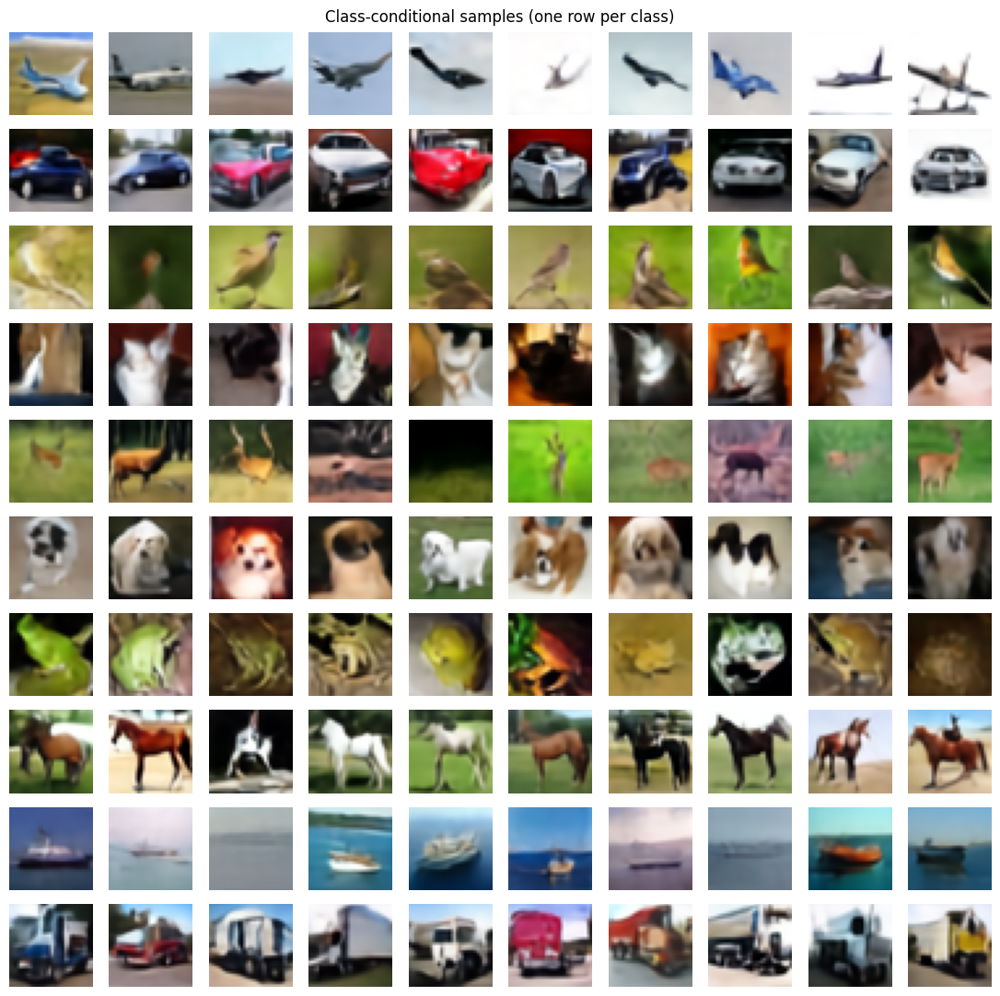

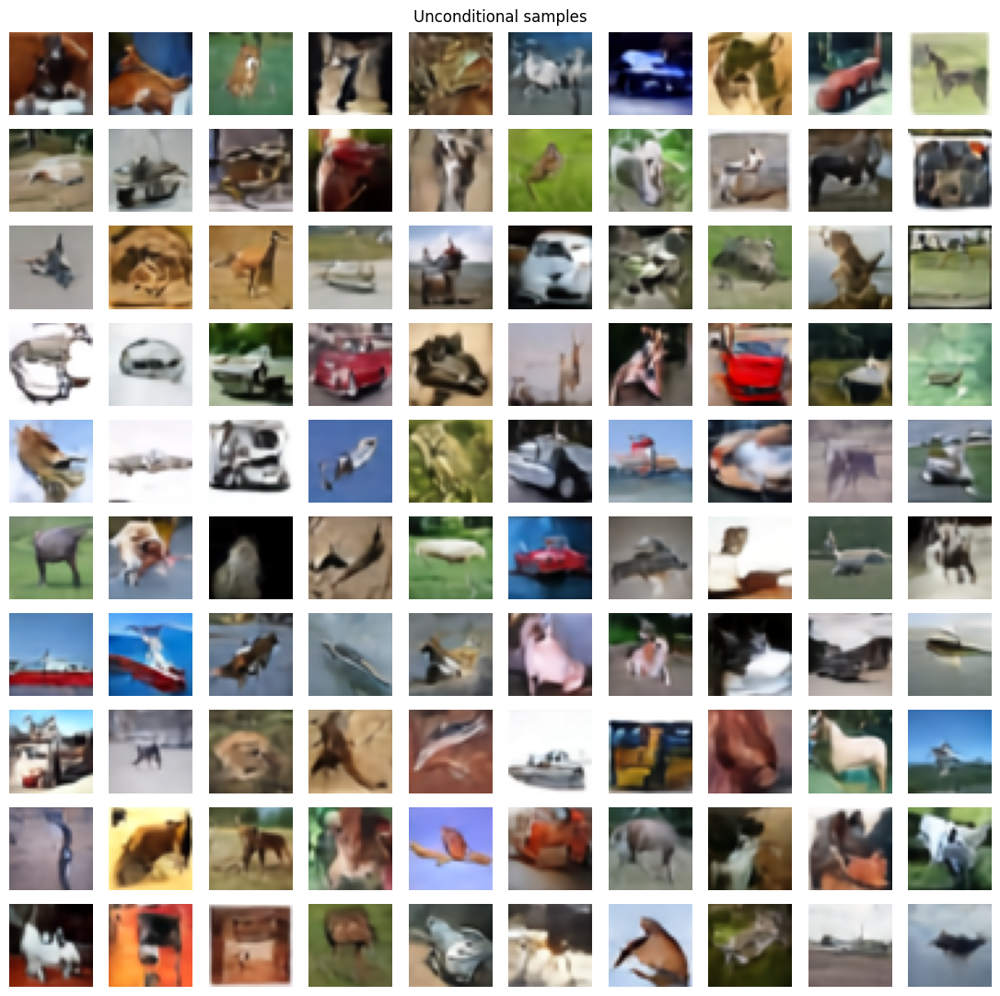

In [21]:
gen = generate(net, CFG["n_fid"], guidance=CFG["guidance"], temperature=CFG["temperature"])
gen_u = generate(net, CFG["n_fid"], uncond=True, temperature=CFG["temperature"])
FID, FID_U = fid_vs_real(gen), fid_vs_real(gen_u)

show_table(["model", "settings", "FID (10k)", "target < 40"], [
    ["Autoencoder reconstructions (floor)", "-", f"{RFID:.2f}", "-"],
    ["AR Transformer, unconditional", f"T={CFG['temperature']}", f"{FID_U:.2f}", "PASS" if FID_U < 40 else "FAIL"],
    ["AR Transformer, class-conditional", f"CFG {CFG['guidance']}, T={CFG['temperature']}", f"{FID:.2f}",
     "PASS" if FID < 40 else "FAIL"],
], "4.3 results", align=["left", "left", "right", "left"])

order = torch.cat([torch.arange(c, 100, 10) for c in range(10)])
show_grid(gen[order], 10, "Class-conditional samples (one row per class)", os.path.join(OUT_DIR, "samples_conditional.png"))
show_grid(gen_u[:100], 10, "Unconditional samples", os.path.join(OUT_DIR, "samples_unconditional.png"))

In [22]:
!pip install -q lpips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 1.3 MB/s eta 0:00:00


In [24]:
import lpips

FT = dict(epochs=10, bs=128, lr=1e-4, w_lpips=0.5, w_gan=0.05, eval_every=2, min_psnr=26.0)


def latent(ae, x):
    # the latent the decoder sees: quantised codes for the discrete AE, posterior mean for the continuous AE
    return ae.quant(ae.enc(x))[0] if hasattr(ae, "quant") else ae.encode(x)


class PatchDisc(nn.Module):
    # 32x32 image -> 4x4 grid of real/fake scores (spectral norm keeps the GAN stable)
    def __init__(self, ch=64):
        super().__init__()
        sn = nn.utils.spectral_norm
        self.net = nn.Sequential(
            sn(nn.Conv2d(3, ch, 4, 2, 1)), nn.LeakyReLU(0.2),
            sn(nn.Conv2d(ch, ch * 2, 4, 2, 1)), nn.LeakyReLU(0.2),
            sn(nn.Conv2d(ch * 2, ch * 4, 4, 2, 1)), nn.LeakyReLU(0.2),
            sn(nn.Conv2d(ch * 4, 1, 3, 1, 1)))

    def forward(self, x):
        return self.net(x)


@torch.no_grad()
def recon_metrics(ae):
    # test-set PSNR and reconstruction FID of the current decoder
    imgs, ps = [], []
    for i in range(0, len(X_TEST), 500):
        x = to_float(X_TEST[i:i + 500])
        r = ae.dec(latent(ae, x)).float().clamp(-1, 1)
        mse = ((r - x) / 2).pow(2).flatten(1).mean(1).clamp_min(1e-10)
        ps.append(10 * torch.log10(1.0 / mse))
        imgs.append(to_uint8(r).cpu())
    return torch.cat(ps).mean().item(), fid_vs_real(torch.cat(imgs))


def finetune_decoder(ae):
    ae.enc.eval().requires_grad_(False)                     # encoder frozen -> latents unchanged
    dec = ae.dec
    dec.eval()
    disc = PatchDisc().to(DEVICE)
    lp = lpips.LPIPS(net="vgg", verbose=False).to(DEVICE).eval().requires_grad_(False)
    opt_g = torch.optim.Adam(dec.parameters(), lr=FT["lr"], betas=(0.5, 0.9))
    opt_d = torch.optim.Adam(disc.parameters(), lr=FT["lr"], betas=(0.5, 0.9))

    psnr, rfid = recon_metrics(ae)
    best = (copy.deepcopy(dec.state_dict()), psnr, rfid)
    rows = [["start (MSE-only decoder)", f"{psnr:.2f}", f"{rfid:.2f}", ""]]
    print(f"start: PSNR {psnr:.2f} | rFID {rfid:.2f}")
    n, t0 = len(X_TRAIN), time.time()

    for epoch in range(1, FT["epochs"] + 1):
        dec.train().requires_grad_(True)
        w_gan = FT["w_gan"] if epoch > 1 else 0.0           # epoch 1: let the discriminator warm up
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n - FT["bs"] + 1, FT["bs"]):
            x = to_float(X_TRAIN[perm[i:i + FT["bs"]]])
            x = torch.where(torch.rand(x.shape[0], 1, 1, 1, device=DEVICE) < 0.5, x.flip(3), x)
            with torch.no_grad():
                z = latent(ae, x)
            r = dec(z)
            g_loss = F.mse_loss(r, x) + FT["w_lpips"] * lp(r, x).mean() - w_gan * disc(r).mean()
            opt_g.zero_grad(set_to_none=True); g_loss.backward(); opt_g.step()
            d_loss = F.relu(1 - disc(x)).mean() + F.relu(1 + disc(r.detach())).mean()
            opt_d.zero_grad(set_to_none=True); d_loss.backward(); opt_d.step()

        if epoch % FT["eval_every"] == 0 or epoch == FT["epochs"]:
            dec.eval()
            psnr, rfid = recon_metrics(ae)
            kept = psnr >= FT["min_psnr"] and rfid < best[2]
            if kept:
                best = (copy.deepcopy(dec.state_dict()), psnr, rfid)
            rows.append([f"epoch {epoch}", f"{psnr:.2f}", f"{rfid:.2f}", "best so far" if kept else ""])
            print(f"epoch {epoch:2d} | PSNR {psnr:.2f} | rFID {rfid:.2f} | {(time.time() - t0) / 60:.1f} min")

    dec.load_state_dict(best[0])
    dec.eval().requires_grad_(False)
    show_table(["decoder", "test PSNR", "reconstruction FID", ""], rows,
               f"Decoder fine-tuning (kept: PSNR {best[1]:.2f}, rFID {best[2]:.2f})",
               align=["left", "right", "right", "left"])
    return best[1], best[2]

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 253MB/s] 


start: PSNR 30.90 | rFID 29.85
epoch  2 | PSNR 29.74 | rFID 9.24 | 8.0 min
epoch  4 | PSNR 29.43 | rFID 8.54 | 15.8 min
epoch  6 | PSNR 29.06 | rFID 9.00 | 23.7 min
epoch  8 | PSNR 29.22 | rFID 8.75 | 31.5 min
epoch 10 | PSNR 29.14 | rFID 11.57 | 39.3 min


decoder,test PSNR,reconstruction FID,
start (MSE-only decoder),30.90,29.85,
epoch 2,29.74,9.24,best so far
epoch 4,29.43,8.54,best so far
epoch 6,29.06,9.00,
epoch 8,29.22,8.75,
epoch 10,29.14,11.57,


model,decoder,FID (10k),target < 40
Autoencoder reconstructions (floor),"fine-tuned, PSNR 29.43",8.54,-
"AR Transformer, unconditional",fine-tuned,27.36,PASS
"AR Transformer, class-conditional",fine-tuned,18.11,PASS


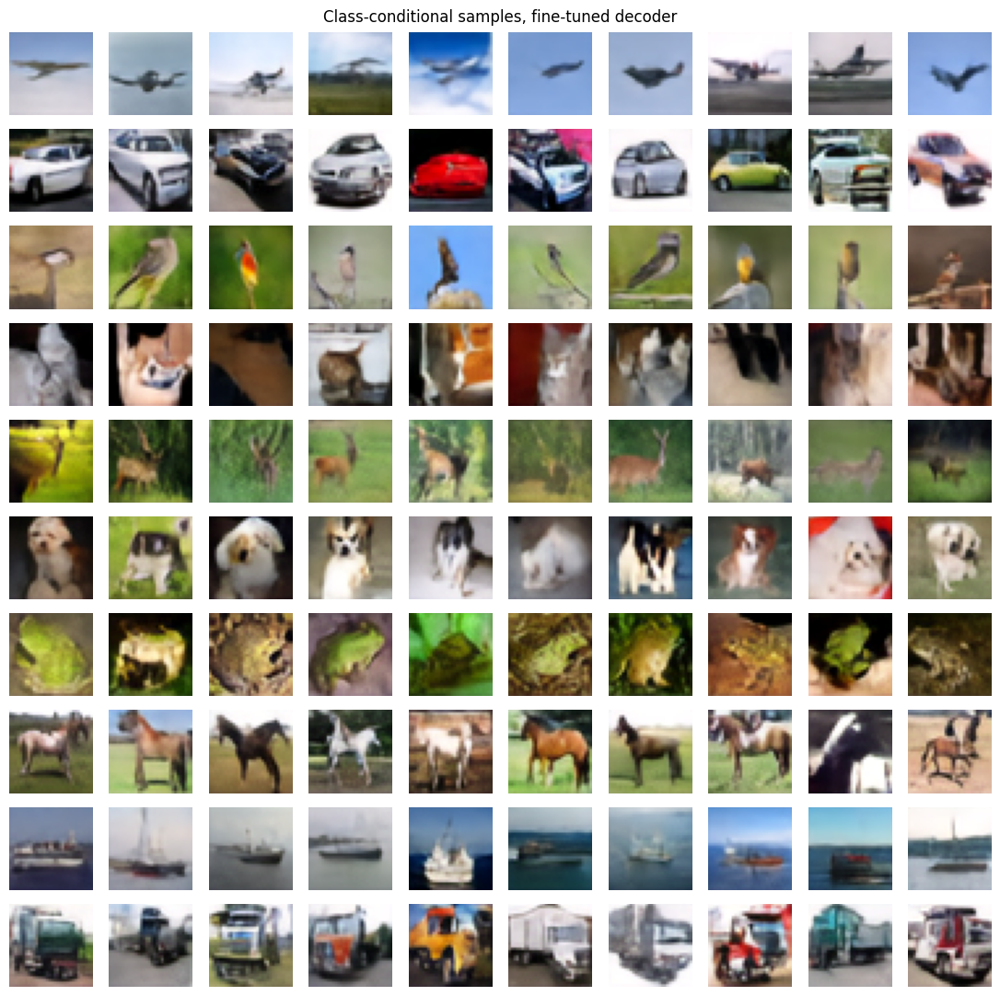

In [25]:
ft_psnr, ft_rfid = finetune_decoder(ae)
torch.save(ae.dec.state_dict(), os.path.join(OUT_DIR, "continuous_decoder_ft.pt"))

gen = generate(net, CFG["n_fid"], guidance=CFG["guidance"], temperature=CFG["temperature"])
gen_u = generate(net, CFG["n_fid"], uncond=True, temperature=CFG["temperature"])
FID, FID_U = fid_vs_real(gen), fid_vs_real(gen_u)

show_table(["model", "decoder", "FID (10k)", "target < 40"], [
    ["Autoencoder reconstructions (floor)", f"fine-tuned, PSNR {ft_psnr:.2f}", f"{ft_rfid:.2f}", "-"],
    ["AR Transformer, unconditional", "fine-tuned", f"{FID_U:.2f}", "PASS" if FID_U < 40 else "FAIL"],
    ["AR Transformer, class-conditional", "fine-tuned", f"{FID:.2f}", "PASS" if FID < 40 else "FAIL"],
], f"4.3 results with fine-tuned decoder (CFG {CFG['guidance']}, T={CFG['temperature']})",
   align=["left", "left", "right", "left"])
order = torch.cat([torch.arange(c, 100, 10) for c in range(10)])
show_grid(gen[order], 10, "Class-conditional samples, fine-tuned decoder",
          os.path.join(OUT_DIR, "samples_conditional_ftdec.png"))

In [26]:
net = LatentARTransformer(D, P, N_CLASSES, CFG).to(DEVICE)
net.load_state_dict(torch.load(os.path.join(OUT_DIR, "latent_ar_transformer.pt"), weights_only=False)["model"])
net.eval()

LatentARTransformer(
  (inp): Linear(in_features=5, out_features=512, bias=True)
  (cls_emb): Embedding(11, 512)
  (blocks): ModuleList(
    (0-7): 8 x Block(
      (ln1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
      (qkv): Linear(in_features=512, out_features=1536, bias=True)
      (proj): Linear(in_features=512, out_features=512, bias=True)
      (ln2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
      (mlp): Sequential(
        (0): Linear(in_features=512, out_features=2048, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=2048, out_features=512, bias=True)
      )
      (drop): Dropout(p=0.1, inplace=False)
    )
  )
  (ln_f): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  (head): DiffusionHead(
    (inp): Linear(in_features=5, out_features=512, bias=True)
    (t_mlp): Sequential(
      (0): Linear(in_features=512, out_features=512, bias=True)
      (1): SiLU()
      (2): Li